# Delta-Ripple Sequence Coupling: Full Dataset

Delta-ripple analysis in one notebook: per-day measures, pooled histograms and significance, trends over time, block plots and ripple-anchored proportions.

---
# Setup

## Configuration

In [9]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import spearmanr

# lab repo root on the path, so `modules` imports work from this folder
REPO_ROOT = next(
    p
    for p in [Path.cwd(), *Path.cwd().parents]
    if (p / "modules" / "project_config.py").exists()
)
sys.path.insert(0, str(REPO_ROOT))
from modules.project_config import get_path  # noqa: E402

# local paths come from config.yaml (see config.example.yaml)
ROOT = get_path("R1_8_root")  # holds Rat_HM_Ephys_TD_Analysis_R1_8 and _R9_16
assert get_path("R9_16_root") == ROOT, "these notebooks expect R1_8_root == R9_16_root"
WAVE_CACHE = get_path("event_cache_root")
SESSION_MAP_CSV = get_path("session_map_csv")
DAY_GRID_XLSX = get_path("day_grid_xlsx")
OUT = REPO_ROOT / "results" / "leticia_event_coupling"  # figures and caches
SPINDLE_METHOD = "wavelet_amp_1_ampcore_3"
PHASES = ["postsleep"]

BOUT_KEYS = ["rat", "date", "trial", "nrem_bout_index"]
AREAS = ["PL", "RSC", "HPC"]
RATS = [1, 3, 7, 8, 11, 12, 13]

# per-day circular shift is the slow part (~200 rat-days x 3 areas x N_ITER)
# 1000 iterations (Yixiao, Sept 2026), with 200 the smallest p is 0.005
N_ITER = 1000
SHIFT_RATS = RATS  # all seven rats (full data),

# RD = ripple leads (50-250 ms), DR = delta leads (50-400 ms)
MEASURES = ["rate_RD", "ratio_RD", "prop_ripples", "rate_DR", "ratio_DR"]
MIN_PAIRS = 0  # no threshold: see the NREM-duration cutoff below,
# which replaces the old ad hoc threshold check

FIGDIR = OUT / "task2_delta_ripple_figures"
FIGDIR.mkdir(parents=True, exist_ok=True)


def save_fig(fig, name):
    fig.savefig(FIGDIR / f"{name}.png", dpi=200, bbox_inches="tight")
    print("saved:", name)


print("drive reachable:", ROOT.exists(), " (False is fine - we load from WAVE_CACHE)")
print("rats:", RATS, "| circular shift on:", SHIFT_RATS, "|", N_ITER, "iterations")

drive reachable: True  (False is fine - we load from WAVE_CACHE)
rats: [1, 3, 7, 8, 11, 12, 13] | circular shift on: [1, 3, 7, 8, 11, 12, 13] | 1000 iterations


## Load

Bad days are removed in `build_wave` (`excluded_days.py`).

In [10]:
from modules.event_coupling.build_tables import add_condition, build_wave

ripples = add_condition(
    build_wave(ROOT, "ripple", SPINDLE_METHOD, PHASES, WAVE_CACHE, rebuild=False),
    SESSION_MAP_CSV,
)
deltas = add_condition(
    build_wave(ROOT, "delta", SPINDLE_METHOD, PHASES, WAVE_CACHE, rebuild=False),
    SESSION_MAP_CSV,
)

rip = ripples[(ripples["rat"].isin(RATS)) & (ripples["group"] != "other")]
dlt = deltas[
    (deltas["rat"].isin(RATS))
    & (deltas["group"] != "other")
    & (deltas["area"].isin(AREAS))
]

print(f"{len(rip):,} ripples | {len(dlt):,} deltas")
print(rip.groupby("group").size().to_string())

ripple: 16 units to gather
  excluded 18,567 rows from 16 bad recording days
  36,373 rows had no trial number (16 rat-days) -> filled with 1
delta: 48 units to gather
  excluded 212,132 rows from 16 bad recording days
  324,368 rows had no trial number (16 rat-days) -> filled with 1
515,364 ripples | 3,844,103 deltas
group
HC          188361
Training    327003


### Check that the bad days were dropped

In [15]:
from modules.event_coupling.excluded_days import excluded_table

ex = excluded_table()
check = ex.merge(
    rip[["rat", "date"]]
    .assign(date=pd.to_datetime(rip["date"]).dt.normalize())
    .drop_duplicates(),
    on=["rat", "date"],
)
print(
    f"{len(ex)} rat-days on the exclusion list | still present in the data: {len(check)} (want 0)"
)
assert len(check) == 0, "exclusion did not fire - is excluded_days.py in this folder?"

42 rat-days on the exclusion list | still present in the data: 0 (want 0)


## Time labels

In [16]:
from modules.event_coupling.gl_sessions import add_gl_sessions, build_gl_sessions
from modules.event_coupling.hc_sessions import add_session_type, build_day_table


def prep_keys(df):
    df = df.copy()
    df["date"] = pd.to_datetime(df["date"]).dt.normalize()
    df["rat"] = df["rat"].astype("int64")
    return df


gl = prep_keys(build_gl_sessions(ROOT, cache_dir=WAVE_CACHE, rebuild=False))
days = add_session_type(build_day_table(DAY_GRID_XLSX, verbose=False))


def add_context(df):
    df = add_gl_sessions(prep_keys(df), gl)
    return df.merge(
        prep_keys(days)[["rat", "date", "session_type"]].drop_duplicates(),
        on=["rat", "date"],
        how="left",
    )


rip_ctx = add_context(rip)
dlt_ctx = add_context(dlt)

# days since each rat's first recording (gaps between sessions are 1-7 days)
first = rip_ctx.groupby("rat")["date"].transform("min")
rip_ctx["days_elapsed"] = (rip_ctx["date"] - first).dt.days
dlt_ctx = dlt_ctx.merge(
    rip_ctx[["rat", "date", "days_elapsed"]].drop_duplicates(),
    on=["rat", "date"],
    how="left",
)

print(
    rip_ctx.groupby(["rat", "group"])["date"]
    .nunique()
    .unstack(fill_value=0)
    .to_string()
)

group  HC  Training
rat                
1       7        12
3      11        20
7       5        10
8      10        20
11     12        19
12     12        19
13     10        19


# Per-day measures

## Five measures for every rat-day

Rate and proportion both tracked (Maingret report both; rate can drop while proportion rises).

| Measure | What it is | Counting unit |
|---|---|---|
| `rate_RD` | sequences per NREM minute, ripple->delta (50-250 ms) | pairs |
| `ratio_RD` | observed / chance, same window | pairs |
| `prop_ripples` | fraction of ripples with a delta 50-250 ms after | unique ripples |
| `rate_DR` | sequences per NREM minute, delta->ripple (50-400 ms) | pairs |
| `ratio_DR` | observed / chance, same window | pairs |

`prop_ripples` counts each ripple once (Yixiao's rule), like Maingret Fig. 2e.

Argument order sets the direction: `count_sequences_unique(rg, dg, "ripple", "delta")` = R->D.

Chance = flat tails of the day's lag histogram (beyond +/-800 ms).

In [17]:
from modules.event_coupling import lag_histogram as lh
from modules.event_coupling.coupling_unique import count_sequences_unique

edges = lh.DEFAULT_EDGES
left = edges[:-1]


def per_day(dlt_df, rip_df, area, min_pairs=MIN_PAIRS):
    """Five measures for each rat x recording day, one delta area."""
    d = dlt_df[dlt_df["area"] == area]
    rows = []
    for (rat, date), dg in d.groupby(["rat", "date"]):
        rg = rip_df[(rip_df["rat"] == rat) & (rip_df["date"] == date)]
        if rg.empty:
            continue

        lg = lh.collect_lags(dg, rg, "delta", "ripple")
        if len(lg) < max(min_pairs, 1):
            continue
        res = lh.summarise(lg, edges, verbose=False)
        w_rd = res["windows"]["R->D"]  # ripple leads, 50-250 ms
        w_dr = res["windows"]["D->R"]  # delta leads,  50-400 ms

        nrem_min = (
            rg[BOUT_KEYS + ["nrem_bout_duration_s"]]
            .drop_duplicates(BOUT_KEYS)["nrem_bout_duration_s"]
            .sum()
            / 60
        )
        if nrem_min <= 0:
            continue

        # each ripple counted once; ripple first = R->D
        u = count_sequences_unique(rg, dg, "ripple", "delta")
        n_coupled = u["n_sequences"].sum()
        n_rip_tot = u["n_ripple"].sum()

        rows.append(
            {
                "rat": rat,
                "date": date,
                "area": area,
                # ripple -> delta
                "rate_RD": w_rd["observed"] / nrem_min,
                "ratio_RD": w_rd["ratio"],
                "n_seq": w_rd["observed"],
                # proportion of ripples (unique-ripple rule)
                "prop_ripples": n_coupled / n_rip_tot if n_rip_tot else np.nan,
                "n_ripple_coupled": int(n_coupled),
                # delta -> ripple
                "rate_DR": w_dr["observed"] / nrem_min,
                "ratio_DR": w_dr["ratio"],
                "n_seq_DR": w_dr["observed"],
                # context
                "pairs": len(lg),
                "n_ripple": len(rg),
                "nrem_min": nrem_min,
                "peak_ms": res["peak_ms"],
                "group": dg["group"].iloc[0],
                "session_type": dg["session_type"].iloc[0],
                "gl_num": dg["gl_num"].iloc[0],
                "session_num": dg["session_num"].iloc[0],
                "days_elapsed": dg["days_elapsed"].iloc[0],
            }
        )
    return pd.DataFrame(rows)


daily = pd.concat([per_day(dlt_ctx, rip_ctx, a) for a in AREAS], ignore_index=True)

print(f"{len(daily)} rat-day-area values")

# --- how much data is behind each daily value ---
print("sequences per recording day:")
print(
    daily.groupby(["area", "group"])
    .agg(
        days=("date", "nunique"),
        rats=("rat", "nunique"),
        seq_RD_median=("n_seq", "median"),
        seq_RD_min=("n_seq", "min"),
        coupled_ripples_median=("n_ripple_coupled", "median"),
        seq_DR_median=("n_seq_DR", "median"),
        ripples_median=("n_ripple", "median"),
    )
    .round(0)
    .to_string()
)


# --- the measures ---
stats = daily.groupby("area")[MEASURES].agg(["median", "mean", "std"]).round(3)
print(stats.to_string())

print("measures by area and condition:")
for m in MEASURES:
    print(f"\n--- {m} ---")
    print(
        daily.groupby(["area", "group"])[m]
        .agg(median="median", mean="mean", std="std", n="size")
        .round(3)
        .to_string()
    )

558 rat-day-area values
sequences per recording day:
               days  rats  seq_RD_median  seq_RD_min  coupled_ripples_median  seq_DR_median  ripples_median
area group                                                                                                 
HPC  HC          41     7          943.0         417                   943.0         1120.0          2778.0
     Training    78     7          921.0         130                   921.0         1045.0          2417.0
PL   HC          41     7          658.0         287                   660.0         1023.0          2778.0
     Training    78     7          594.0         105                   596.0          918.0          2417.0
RSC  HC          41     7          729.0         347                   733.0         1116.0          2778.0
     Training    78     7          651.0         111                   654.0          979.0          2417.0
     rate_RD               ratio_RD               prop_ripples               rate_D

In [18]:
print("total sequences across the whole dataset:")
tot = daily.groupby("area").agg(
    rat_days=("date", "size"),
    seq_RD=("n_seq", "sum"),
    coupled_ripples=("n_ripple_coupled", "sum"),
    seq_DR=("n_seq_DR", "sum"),
    ripples=("n_ripple", "sum"),
    nrem_hours=("nrem_min", lambda s: s.sum() / 60),
)
print(tot.round(0).to_string())

print("and split by condition:")
print(
    daily.groupby(["area", "group"])
    .agg(
        rat_days=("date", "size"),
        seq_RD=("n_seq", "sum"),
        coupled_ripples=("n_ripple_coupled", "sum"),
        ripples=("n_ripple", "sum"),
    )
    .round(0)
    .to_string()
)

total sequences across the whole dataset:
      rat_days  seq_RD  coupled_ripples  seq_DR  ripples  nrem_hours
area                                                                
HPC        186  196772           197360  214190   515364       345.0
PL         186  120035           120385  185192   515364       345.0
RSC        186  136662           137287  198593   515364       345.0
and split by condition:
               rat_days  seq_RD  coupled_ripples  ripples
area group                                               
HPC  HC              67   71259            71471   188361
     Training       119  125513           125889   327003
PL   HC              67   43972            44094   188361
     Training       119   76063            76291   327003
RSC  HC              67   50655            50885   188361
     Training       119   86007            86402   327003


# Pooled coupling result

          PL: pairs 1,054,252 | peak  -140 ms | + 38.7% above baseline | R->D 1.154x | D->R 1.017x
         RSC: pairs 1,142,391 | peak  -120 ms | + 65.9% above baseline | R->D 1.252x | D->R 1.040x
         HPC: pairs 1,209,239 | peak  -140 ms | +168.7% above baseline | R->D 1.748x | D->R 1.087x
saved: 10_histogram_by_area


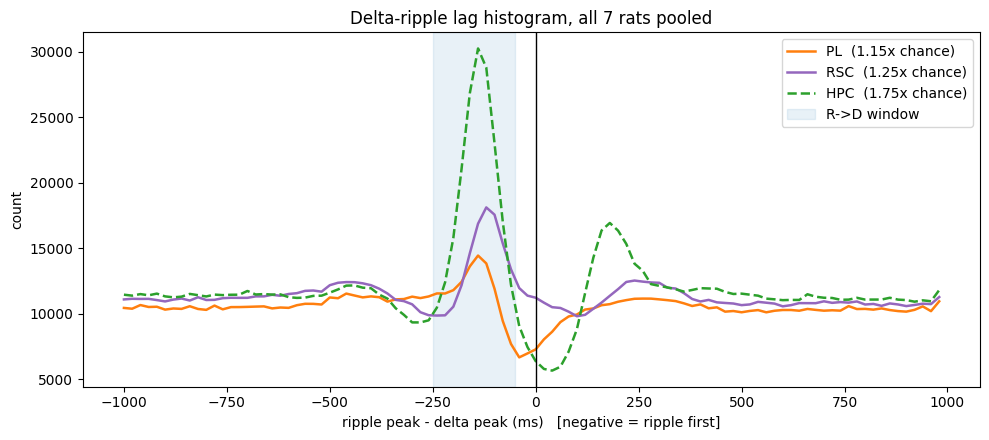

In [19]:
# pooled lag histogram per area, absolute counts (Yixiao, 2 Sep 2026)
fig = plt.figure(figsize=(10, 4.5))
pooled = {}
for area, colour, style in [
    ("PL", "tab:orange", "-"),
    ("RSC", "tab:purple", "-"),
    ("HPC", "tab:green", "--"),
]:
    lg = lh.collect_lags(dlt_ctx[dlt_ctx["area"] == area], rip_ctx, "delta", "ripple")
    r = lh.summarise(lg, edges, label=area)
    pooled[area] = r
    plt.plot(
        left,
        r["counts"],
        style,
        color=colour,
        lw=1.8,
        label=f"{area}  ({r['windows']['R->D']['ratio']:.2f}x chance)",
    )

plt.axvspan(-250, -50, color="tab:blue", alpha=0.10, label="R->D window")
plt.axvline(0, color="k", lw=1)
plt.xlabel("ripple peak - delta peak (ms)   [negative = ripple first]")
plt.ylabel("count")
plt.title("Delta-ripple lag histogram, all 7 rats pooled")
plt.legend()
plt.tight_layout()
save_fig(fig, "10_histogram_by_area")
plt.show()

saved: 11_histogram_perrat_PL


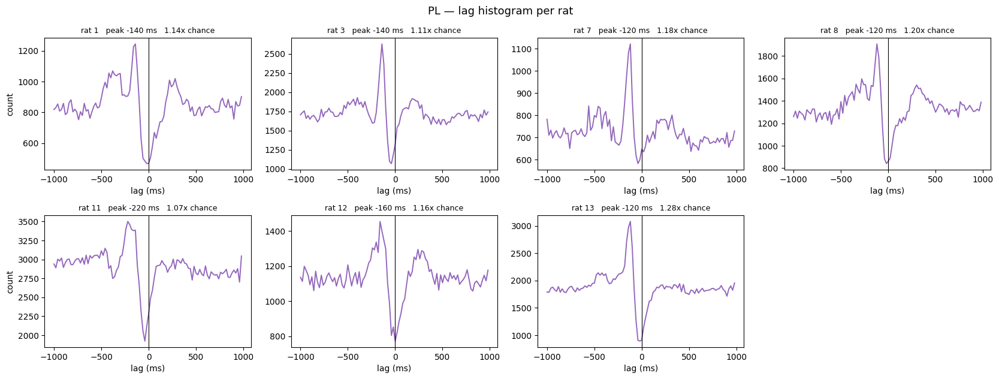

saved: 11_histogram_perrat_RSC


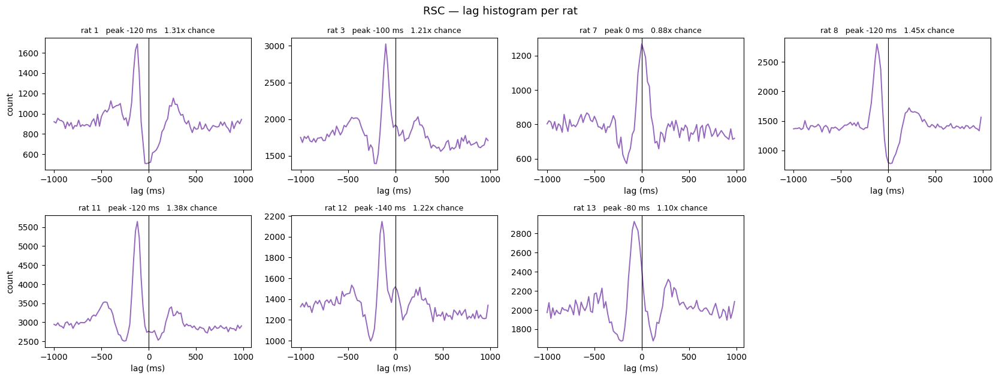

saved: 11_histogram_perrat_HPC


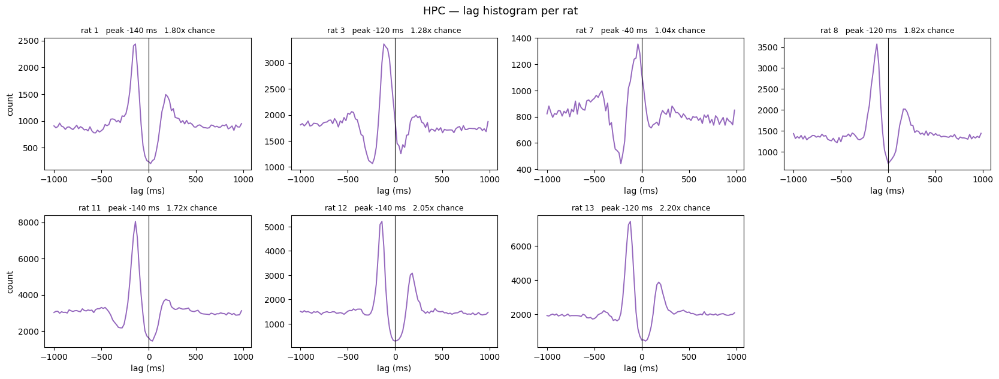

In [20]:
# per rat, all areas, to check the pooled shape holds in single rats (no significance here)
for area in AREAS:
    rats = sorted(rip_ctx["rat"].unique())
    ncol = 4
    nrow = int(np.ceil(len(rats) / ncol))
    fig, axes = plt.subplots(
        nrow, ncol, figsize=(4.2 * ncol, 3.2 * nrow), sharey=False, squeeze=False
    )
    for ax, rat in zip(axes.ravel(), rats):
        lg = lh.collect_lags(
            dlt_ctx[(dlt_ctx["area"] == area) & (dlt_ctx["rat"] == rat)],
            rip_ctx[rip_ctx["rat"] == rat],
            "delta",
            "ripple",
        )
        if len(lg) < 500:
            ax.set_title(f"rat {rat}: too few pairs")
            continue
        r = lh.summarise(lg, edges, verbose=False)
        ax.plot(left, r["counts"], lw=1.4, color="tab:purple")
        ax.axvline(0, color="k", lw=0.8)
        ax.set_title(
            f"rat {rat}   peak {r['peak_ms']} ms   "
            f"{r['windows']['R->D']['ratio']:.2f}x chance",
            fontsize=9,
        )
        ax.set_xlabel("lag (ms)")
    for ax in axes.ravel()[len(rats) :]:
        ax.axis("off")
    for row in axes:
        row[0].set_ylabel("count")
    fig.suptitle(f"{area} — lag histogram per rat", fontsize=13)
    plt.tight_layout()
    save_fig(fig, f"11_histogram_perrat_{area}")
    plt.show()

In [21]:
from modules.event_coupling.coupling_unique import count_sequences_unique

for area in AREAS:
    d = dlt_ctx[dlt_ctx["area"] == area]
    u = count_sequences_unique(d, rip_ctx, "delta", "ripple")
    coupled = u["n_sequences"].sum()
    total = u["n_delta"].sum()
    print(
        f"{area:>4}: {coupled:>9,} of {total:>10,} delta waves "
        f"({100 * coupled / total:5.1f}%)"
    )

  PL:   183,113 of  1,247,627 delta waves ( 14.7%)
 RSC:   195,601 of  1,285,229 delta waves ( 15.2%)
 HPC:   211,478 of  1,311,247 delta waves ( 16.1%)


# Significance test (1000 iterations, with checkpoints)

In [22]:
def plot_with_significance(dist, edges, area, window_ms, label=None, ax=None):
    """Lag histogram in absolute counts, with a significance bar over the
    tested window when the observed sum beats the shuffled null
    (Yixiao, 2 Sep 2026 -- see her reference figure).

    Shows the null distribution's spread (+/-2 SD band), matching the style
    already used in the ripple-spindle overlap plots.
    """
    left = edges[:-1]
    real = dist["real"]
    null = dist["null"]
    mu, sd = null.mean(axis=0), null.std(axis=0)

    res = window_significance(dist, edges, window_ms)

    own_fig = ax is None
    if own_fig:
        fig, ax = plt.subplots(figsize=(9, 4.5))

    ax.bar(left, real, width=20, align="edge", color="0.35", zorder=2)
    ax.plot(left, mu, color="0.5", lw=1, zorder=3, label="null mean")
    ax.fill_between(
        left,
        mu - 2 * sd,
        mu + 2 * sd,
        color="tab:orange",
        alpha=0.25,
        zorder=1,
        label="null \u00b12 SD",
    )
    ax.axvline(0, color="k", lw=1)

    lo, hi = window_ms
    if res["significant"]:
        y_bar = real.max() * 1.08
        ax.plot([lo, hi], [y_bar, y_bar], color="tab:red", lw=3, zorder=4)
        p_str = "p < 0.001" if res["p"] < 0.001 else f"p = {res['p']:.3f}"
        ax.text(
            (lo + hi) / 2,
            y_bar * 1.03,
            p_str,
            ha="center",
            fontsize=11,
            color="tab:red",
            fontweight="bold",
        )
        ax.set_ylim(top=y_bar * 1.25)
    else:
        ax.axvspan(lo, hi, color="tab:blue", alpha=0.08, zorder=0)
        ax.text(
            (lo + hi) / 2,
            real.max() * 1.05,
            "n.s.",
            ha="center",
            fontsize=10,
            color="tab:blue",
        )

    ax.set_xlabel("ripple peak - delta peak (ms)   [negative = ripple first]")
    ax.set_ylabel("count")
    ax.set_title(label or area)
    ax.legend(fontsize=8, loc="upper right")

    if own_fig:
        plt.tight_layout()
        return fig, res
    return res

In [23]:
from modules.event_coupling import surrogate as sg
from modules.event_coupling.surrogate import window_significance

  100/1000
  200/1000
    [checkpoint saved: 200/1000]
  300/1000
  400/1000
    [checkpoint saved: 400/1000]
  500/1000
  600/1000
    [checkpoint saved: 600/1000]
  700/1000
  800/1000
    [checkpoint saved: 800/1000]
  900/1000
  1000/1000
    [checkpoint saved: 1000/1000]
PL: computed and cached
  100/1000
  200/1000
    [checkpoint saved: 200/1000]
  300/1000
  400/1000
    [checkpoint saved: 400/1000]
  500/1000
  600/1000
    [checkpoint saved: 600/1000]
  700/1000
  800/1000
    [checkpoint saved: 800/1000]
  900/1000
  1000/1000
    [checkpoint saved: 1000/1000]
RSC: computed and cached
  100/1000
  200/1000
    [checkpoint saved: 200/1000]
  300/1000
  400/1000
    [checkpoint saved: 400/1000]
  500/1000
  600/1000
    [checkpoint saved: 600/1000]
  700/1000
  800/1000
    [checkpoint saved: 800/1000]
  900/1000
  1000/1000
    [checkpoint saved: 1000/1000]
HPC: computed and cached
saved: 12_significance_by_area


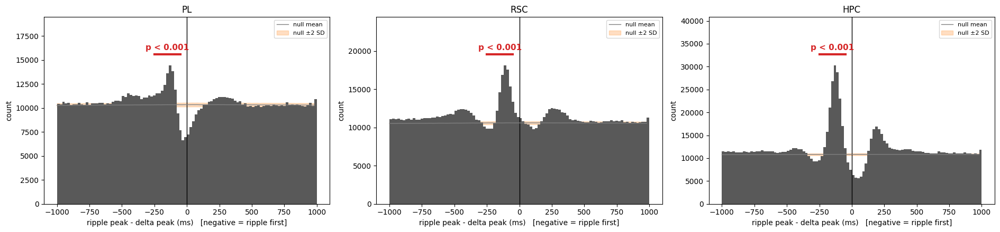

PL: observed 118,154 | null mean 103,395 +/- 285 | p = 0.0010 | significant = True
RSC: observed 138,269 | null mean 105,940 +/- 304 | p = 0.0010 | significant = True
HPC: observed 197,751 | null mean 108,190 +/- 287 | p = 0.0010 | significant = True


In [24]:
import pickle
from pathlib import Path

CACHE_SIG = OUT / "significance_cache"
CACHE_SIG.mkdir(parents=True, exist_ok=True)
R_TO_D_WINDOW = (-250, -50)
D_TO_R_WINDOW = (50, 400)
N_ITER_SIG = 1000
CHECKPOINT_EVERY = 200


def run_with_checkpoints(area):
    final_f = CACHE_SIG / f"dist_{area}_n{N_ITER_SIG}.pkl"
    ckpt_f = CACHE_SIG / f"dist_{area}_n{N_ITER_SIG}_partial.pkl"

    if final_f.exists():
        print(f"{area}: loaded finished result from cache")
        return pickle.load(open(final_f, "rb"))

    resume = None
    if ckpt_f.exists():
        resume = pickle.load(open(ckpt_f, "rb"))
        print(f"{area}: found checkpoint at {resume['n_done']}/{N_ITER_SIG}, resuming")

    def save_checkpoint(partial):
        pickle.dump(partial, open(ckpt_f, "wb"))
        print(f"    [checkpoint saved: {partial['n_done']}/{N_ITER_SIG}]")

    dist = sg.surrogate_distribution(
        dlt[dlt["area"] == area],
        rip,
        "delta",
        "ripple",
        edges,
        n_iter=N_ITER_SIG,
        seed=0,
        scope="recording",
        verbose=True,
        checkpoint_every=CHECKPOINT_EVERY,
        checkpoint_fn=save_checkpoint,
        resume_from=resume,
    )

    pickle.dump(dist, open(final_f, "wb"))
    if ckpt_f.exists():
        ckpt_f.unlink()  # clean up the partial once we have the real one
    print(f"{area}: computed and cached")
    return dist


sig_results = {}
fig, axes = plt.subplots(1, 3, figsize=(19, 4.5))
for ax, area in zip(axes, ["PL", "RSC", "HPC"]):
    dist = run_with_checkpoints(area)
    res = plot_with_significance(dist, edges, area, R_TO_D_WINDOW, label=area, ax=ax)
    sig_results[area] = res

plt.tight_layout()
save_fig(fig, "12_significance_by_area")
plt.show()

for area, r in sig_results.items():
    print(
        f"{area}: observed {r['observed']:,} | null mean {r['null_mean']:,.0f} "
        f"+/- {r['null_sd']:,.0f} | p = {r['p']:.4f} | significant = {r['significant']}"
    )

PL: loaded finished result from cache
RSC: loaded finished result from cache
HPC: loaded finished result from cache
saved: 14_significance_DtoR_by_area


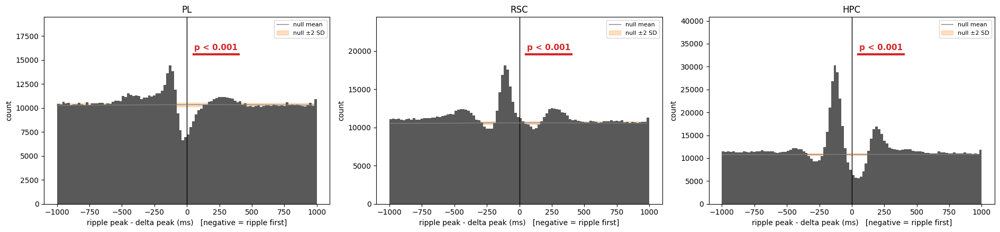

In [25]:
fig, axes = plt.subplots(1, 3, figsize=(19, 4.5))
for ax, area in zip(axes, ["PL", "RSC", "HPC"]):
    dist = run_with_checkpoints(area)  # same cached 1000-iter distributions as above
    res = plot_with_significance(dist, edges, area, D_TO_R_WINDOW, label=area, ax=ax)

plt.tight_layout()
save_fig(fig, "14_significance_DtoR_by_area")
plt.show()

PL: loaded finished result from cache
RSC: loaded finished result from cache
HPC: loaded finished result from cache
saved: 14_ratio_comparison_by_area


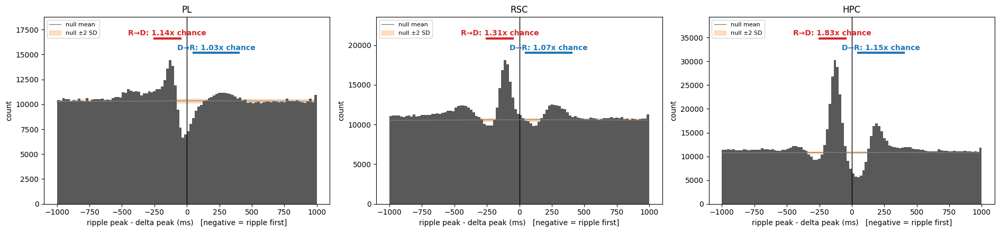

PL: loaded finished result from cache
PL: R→D 1.14x  |  D→R 1.03x
RSC: loaded finished result from cache
RSC: R→D 1.31x  |  D→R 1.07x
HPC: loaded finished result from cache
HPC: R→D 1.83x  |  D→R 1.15x


In [26]:
def plot_ratio_comparison(dist, edges, area, ax=None):
    """R->D vs D->R, shown as ratio-to-chance rather than a significance
    verdict. At this sample size (~200k+ pairs), the null's SD is tiny
    relative to its mean, so nearly every window -- including ones far from
    any real coupling -- clears p < 0.05. The binary flag stops being
    informative; the ratio is what actually distinguishes a real effect
    (R->D, ~1.8x) from a trivial one (D->R, ~1.15x, barely above the
    ~1.03-1.05x seen in windows with no expected coupling at all).
    """
    left = edges[:-1]
    real = dist["real"]
    null = dist["null"]
    mu, sd = null.mean(axis=0), null.std(axis=0)

    own_fig = ax is None
    if own_fig:
        fig, ax = plt.subplots(figsize=(9, 4.5))

    ax.bar(left, real, width=20, align="edge", color="0.35", zorder=2)
    ax.plot(left, mu, color="0.5", lw=1, zorder=3, label="null mean")
    ax.fill_between(
        left,
        mu - 2 * sd,
        mu + 2 * sd,
        color="tab:orange",
        alpha=0.25,
        zorder=1,
        label="null \u00b12 SD",
    )
    ax.axvline(0, color="k", lw=1)

    for lo, hi, label, colour in [
        (-250, -50, "R\u2192D", "tab:red"),
        (50, 400, "D\u2192R", "tab:blue"),
    ]:
        r = window_significance(dist, edges, (lo, hi))
        ratio = r["observed"] / r["null_mean"]
        y_bar = real.max() * (1.15 if colour == "tab:red" else 1.05)
        ax.plot([lo, hi], [y_bar, y_bar], color=colour, lw=3, zorder=4)
        ax.text(
            (lo + hi) / 2,
            y_bar * 1.02,
            f"{label}: {ratio:.2f}x chance",
            ha="center",
            fontsize=10,
            color=colour,
            fontweight="bold",
        )

    ax.set_ylim(top=real.max() * 1.3)
    ax.set_xlabel("ripple peak - delta peak (ms)   [negative = ripple first]")
    ax.set_ylabel("count")
    ax.set_title(area)
    ax.legend(fontsize=8, loc="upper left")

    if own_fig:
        plt.tight_layout()
        return fig
    return None


fig, axes = plt.subplots(1, 3, figsize=(19, 4.5))
for ax, area in zip(axes, ["PL", "RSC", "HPC"]):
    dist = run_with_checkpoints(area)
    plot_ratio_comparison(dist, edges, area, ax=ax)

plt.tight_layout()
save_fig(fig, "14_ratio_comparison_by_area")
plt.show()

for area in ["PL", "RSC", "HPC"]:
    dist = run_with_checkpoints(area)
    rd = window_significance(dist, edges, (-250, -50))
    dr = window_significance(dist, edges, (50, 400))
    print(
        f"{area}: R\u2192D {rd['observed'] / rd['null_mean']:.2f}x  |  "
        f"D\u2192R {dr['observed'] / dr['null_mean']:.2f}x"
    )

In [27]:
rows = []
for area in AREAS:
    dist = run_with_checkpoints(area)
    for lo, hi, label in [(-250, -50, "R->D"), (50, 400, "D->R")]:
        r = window_significance(dist, edges, (lo, hi))
        rows.append(
            {
                "area": area,
                "direction": label,
                "observed": r["observed"],
                "null_mean": round(r["null_mean"]),
                "ratio": round(r["observed"] / r["null_mean"], 3),
                "p": r["p"],
                "significant": r["significant"],
            }
        )

sig_summary = pd.DataFrame(rows)
print(sig_summary.to_string(index=False))

PL: loaded finished result from cache
RSC: loaded finished result from cache
HPC: loaded finished result from cache
area direction  observed  null_mean  ratio        p  significant
  PL      R->D    118154     103395  1.143 0.000999         True
  PL      D->R    180866     175830  1.029 0.000999         True
 RSC      R->D    138269     105940  1.305 0.000999         True
 RSC      D->R    193355     180120  1.073 0.000999         True
 HPC      R->D    197751     108190  1.828 0.000999         True
 HPC      D->R    211359     183994  1.149 0.000999         True


# End-of-delta -> start-of-ripple

Separates delta waves that end before the ripple starts from overlapping pairs. Uses `delta_end_index` -> `ripple_start_index`, D->R only.

`lag = ripple_start - delta_end`: lag < 0 overlap, lag >= 0 sequential.

In [28]:
# wider range and baseline than the peak-to-peak histograms
MAX_LAG_MS_ES = 1600
EDGES_ES = np.arange(-1600, 1620, 20)
BASELINE_ES = 1400
left_es = EDGES_ES[:-1]

res_end_start_dr = {}
for area in AREAS:
    lg = lh.collect_lags_cols(
        dlt_ctx[dlt_ctx["area"] == area],
        rip_ctx,
        "delta_end_index",
        "ripple_start_index",
        max_lag_ms=MAX_LAG_MS_ES,
    )
    res_end_start_dr[area] = lh.summarise(
        lg,
        EDGES_ES,
        baseline_ms=BASELINE_ES,
        windows=[
            ("overlap (lag<0)", -MAX_LAG_MS_ES, 0),
            ("sequential (lag>=0)", 0, MAX_LAG_MS_ES),
        ],
        label=f"{area} delta end - ripple start",
    )

for area, r in res_end_start_dr.items():
    ov = r["windows"]["overlap (lag<0)"]["observed"]
    sq = r["windows"]["sequential (lag>=0)"]["observed"]
    print(
        f"{area}: {ov:,} pairs overlap (lag<0) | {sq:,} pairs sequential (lag>=0) "
        f"| {100 * sq / (ov + sq):.1f}% sequential"
    )

PL delta end - ripple start: pairs 1,670,610 | peak   -20 ms | + 17.6% above baseline | overlap (lag<0) 1.027x | sequential (lag>=0) 1.002x
RSC delta end - ripple start: pairs 1,783,084 | peak  -340 ms | + 40.8% above baseline | overlap (lag<0) 1.065x | sequential (lag>=0) 1.006x
HPC delta end - ripple start: pairs 1,865,307 | peak   -40 ms | +122.6% above baseline | overlap (lag<0) 1.112x | sequential (lag>=0) 1.012x
PL: 845,327 pairs overlap (lag<0) | 824,769 pairs sequential (lag>=0) | 49.4% sequential
RSC: 916,854 pairs overlap (lag<0) | 865,708 pairs sequential (lag>=0) | 48.6% sequential
HPC: 976,135 pairs overlap (lag<0) | 888,611 pairs sequential (lag>=0) | 47.7% sequential


saved: 15_histogram_end_start_PL


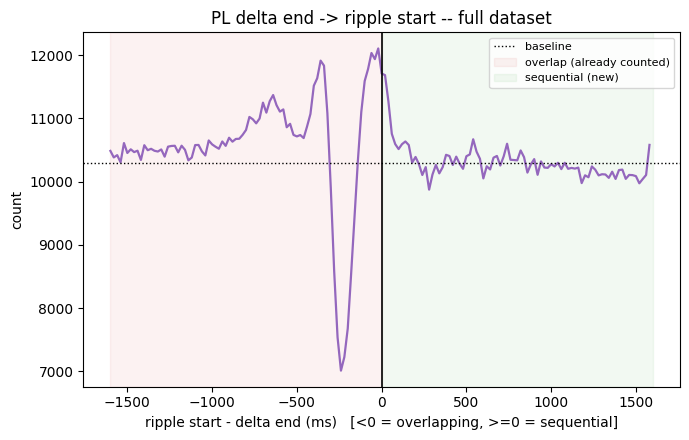

saved: 15_histogram_end_start_RSC


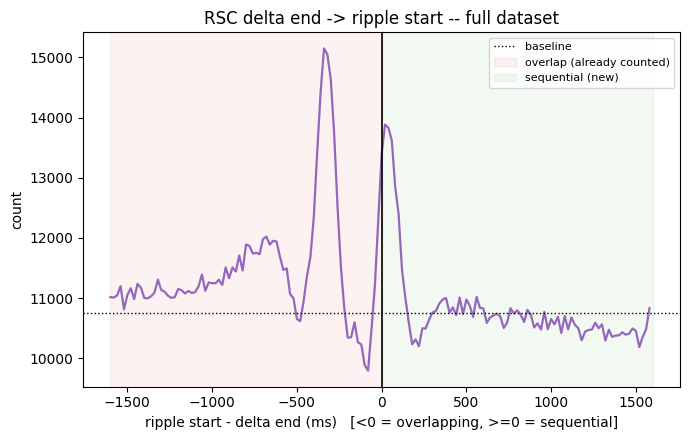

saved: 15_histogram_end_start_HPC


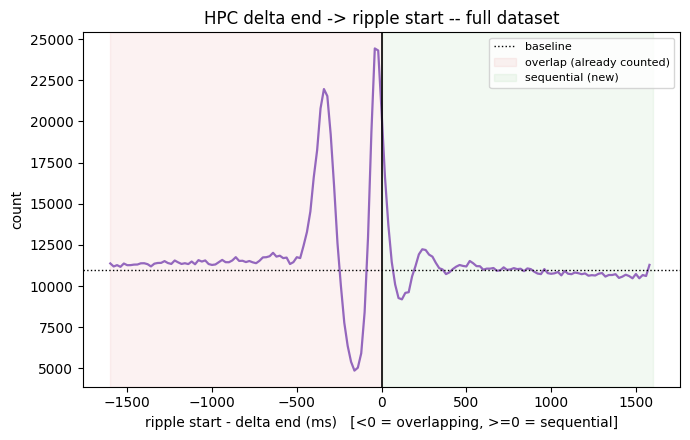

In [35]:
for area, r in res_end_start_dr.items():
    fig, ax = plt.subplots(figsize=(7, 4.5))
    ax.plot(left_es, r["counts"], color="tab:purple", lw=1.6)
    ax.axhline(r["baseline"], color="k", lw=1, ls=":", label="baseline")
    ax.axvline(0, color="k", lw=1.2)
    ax.axvspan(
        EDGES_ES[0], 0, color="tab:red", alpha=0.06, label="overlap (already counted)"
    )
    ax.axvspan(0, EDGES_ES[-1], color="tab:green", alpha=0.06, label="sequential (new)")
    ax.set_xlabel(
        "ripple start - delta end (ms)   [<0 = overlapping, >=0 = sequential]"
    )
    ax.set_ylabel("count")
    ax.set_title(f"{area} delta end -> ripple start -- full dataset")
    ax.legend(fontsize=8)
    plt.tight_layout()
    save_fig(fig, f"15_histogram_end_start_{area}")
    plt.show()

In [36]:
# Per-rat delta end -> ripple start histograms

RAT_COL = "rat"

res_end_start_dr_by_rat = {}

for rat in dlt_ctx[RAT_COL].dropna().unique():

    res_end_start_dr_by_rat[rat] = {}

    # Filter both delta and ripple data for this rat
    dlt_rat = dlt_ctx[dlt_ctx[RAT_COL] == rat]
    rip_rat = rip_ctx[rip_ctx[RAT_COL] == rat]

    for area in AREAS:

        dlt_area = dlt_rat[dlt_rat["area"] == area]

        if dlt_area.empty or rip_rat.empty:
            continue

        lg = lh.collect_lags_cols(
            dlt_area,
            rip_rat,
            "delta_end_index",
            "ripple_start_index",
            max_lag_ms=MAX_LAG_MS_ES,
        )

        res_end_start_dr_by_rat[rat][area] = lh.summarise(
            lg,
            EDGES_ES,
            baseline_ms=BASELINE_ES,
            windows=[
                ("overlap (lag<0)", -MAX_LAG_MS_ES, 0),
                ("sequential (lag>=0)", 0, MAX_LAG_MS_ES),
            ],
            label=f"{rat} {area} delta end - ripple start",
        )

1 PL delta end - ripple start: pairs   134,603 | peak   -20 ms | + 35.0% above baseline | overlap (lag<0) 1.010x | sequential (lag>=0) 1.001x
1 RSC delta end - ripple start: pairs   145,229 | peak    20 ms | + 54.7% above baseline | overlap (lag<0) 1.038x | sequential (lag>=0) 1.000x
1 HPC delta end - ripple start: pairs   147,832 | peak   -40 ms | +180.3% above baseline | overlap (lag<0) 1.122x | sequential (lag>=0) 1.027x
3 PL delta end - ripple start: pairs   272,300 | peak   -20 ms | + 28.9% above baseline | overlap (lag<0) 1.041x | sequential (lag>=0) 1.003x
3 RSC delta end - ripple start: pairs   278,425 | peak  -280 ms | + 48.0% above baseline | overlap (lag<0) 1.103x | sequential (lag>=0) 1.010x
3 HPC delta end - ripple start: pairs   286,388 | peak  -280 ms | + 80.9% above baseline | overlap (lag<0) 1.066x | sequential (lag>=0) 1.004x
13 PL delta end - ripple start: pairs   295,143 | peak  -340 ms | + 29.7% above baseline | overlap (lag<0) 1.038x | sequential (lag>=0) 1.010x
1

saved: 15_histogram_end_start_1_PL


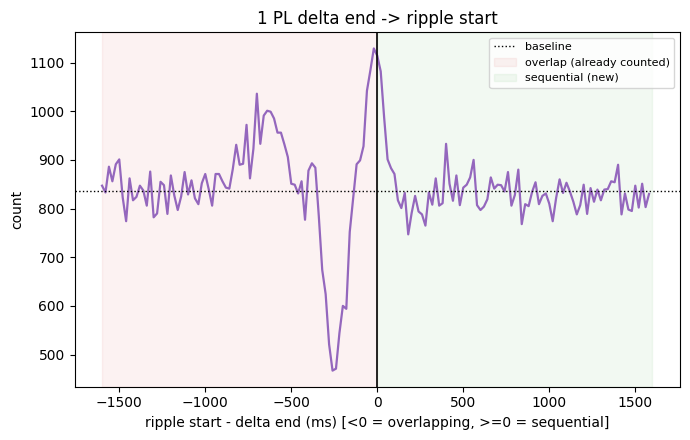

saved: 15_histogram_end_start_1_RSC


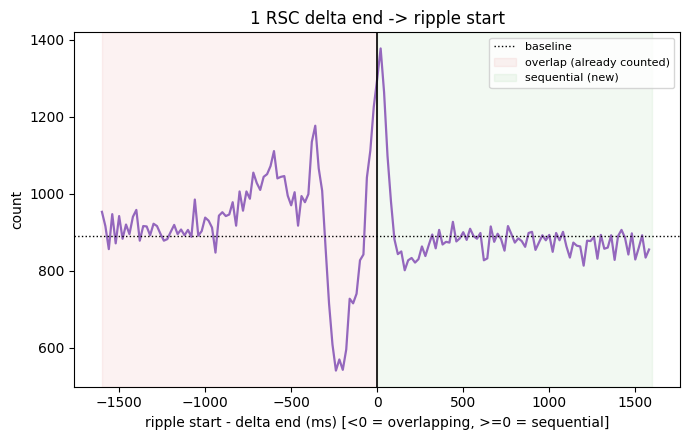

saved: 15_histogram_end_start_1_HPC


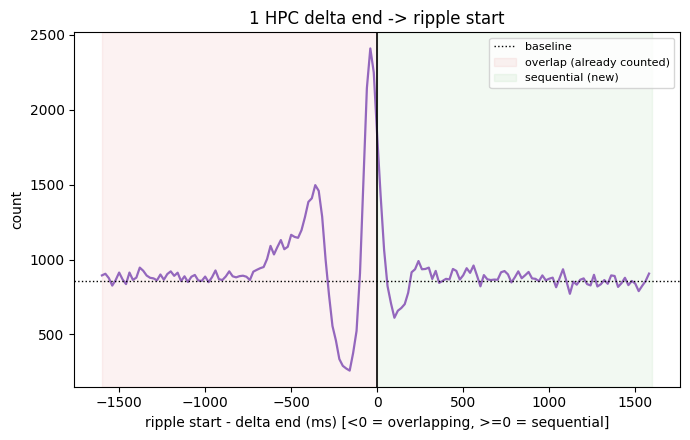

saved: 15_histogram_end_start_3_PL


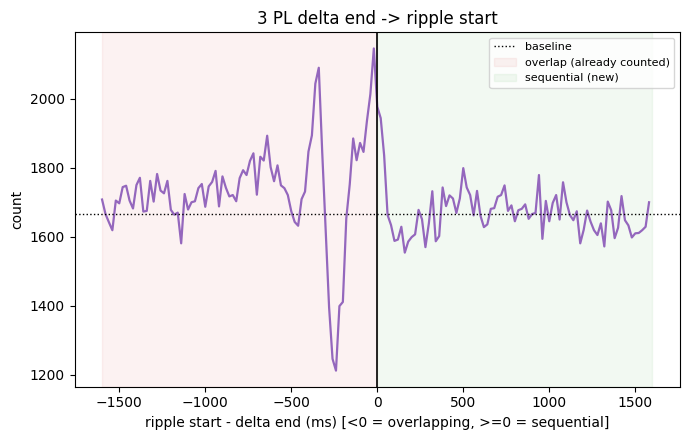

saved: 15_histogram_end_start_3_RSC


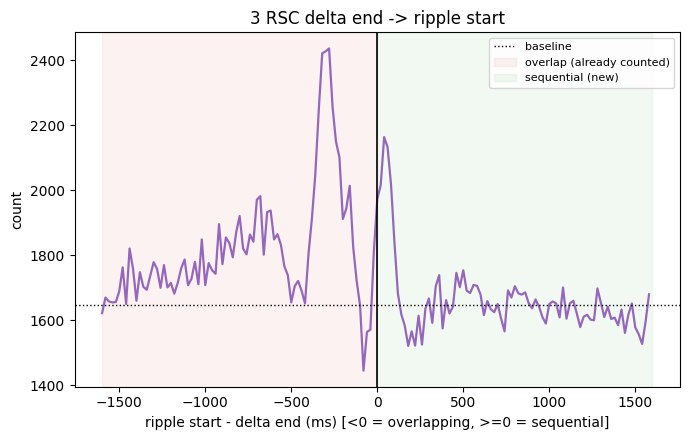

saved: 15_histogram_end_start_3_HPC


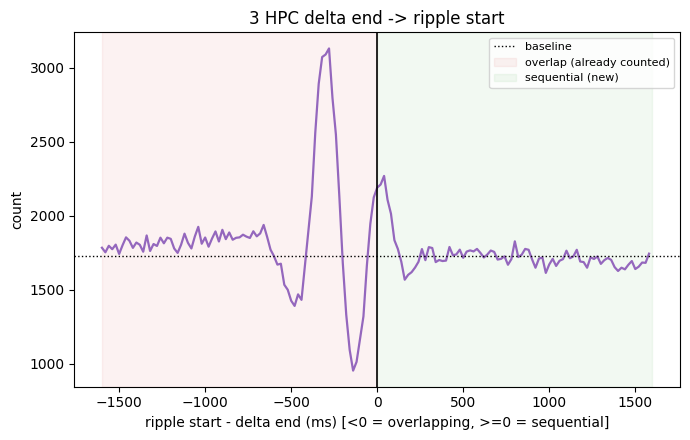

saved: 15_histogram_end_start_13_PL


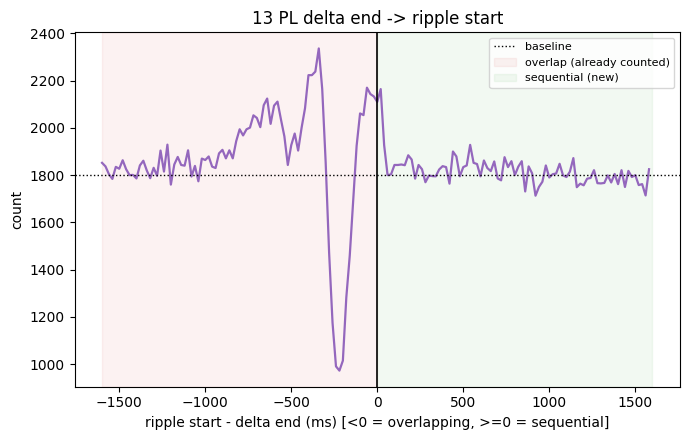

saved: 15_histogram_end_start_13_RSC


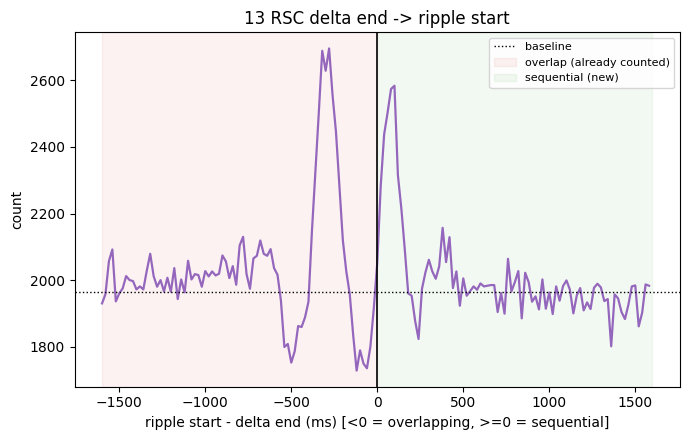

saved: 15_histogram_end_start_13_HPC


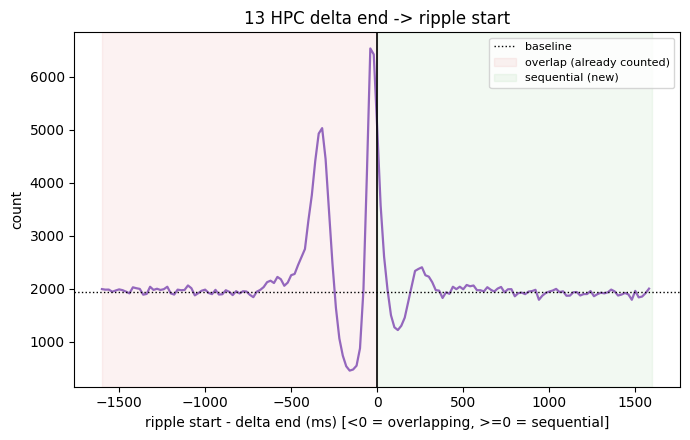

saved: 15_histogram_end_start_7_PL


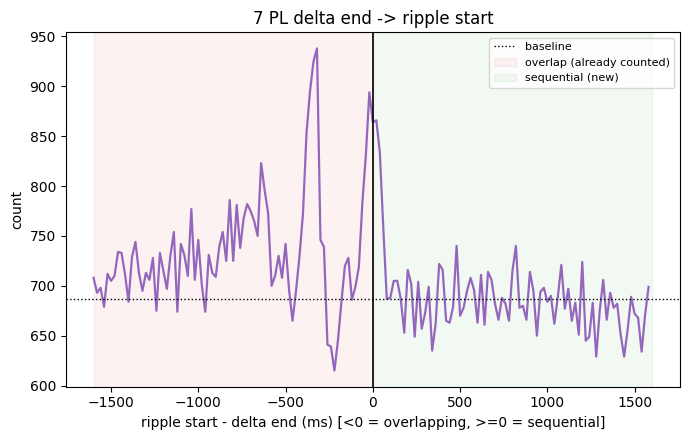

saved: 15_histogram_end_start_7_RSC


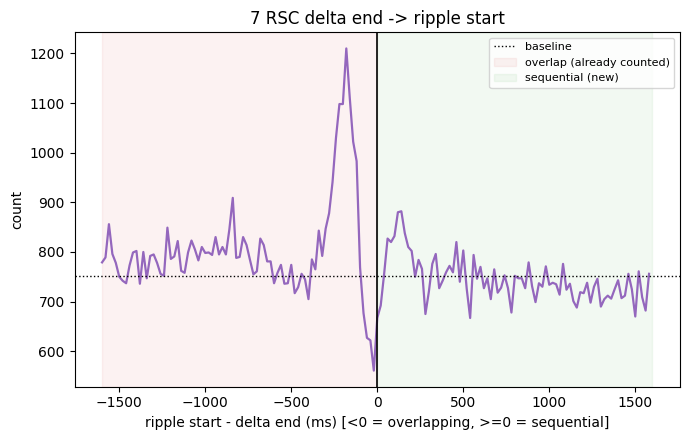

saved: 15_histogram_end_start_7_HPC


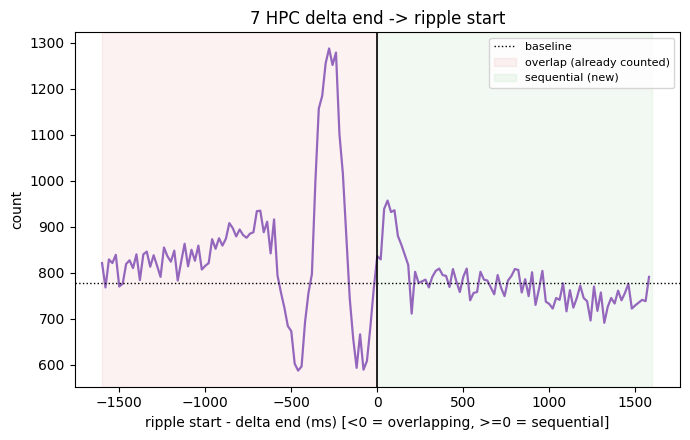

saved: 15_histogram_end_start_8_PL


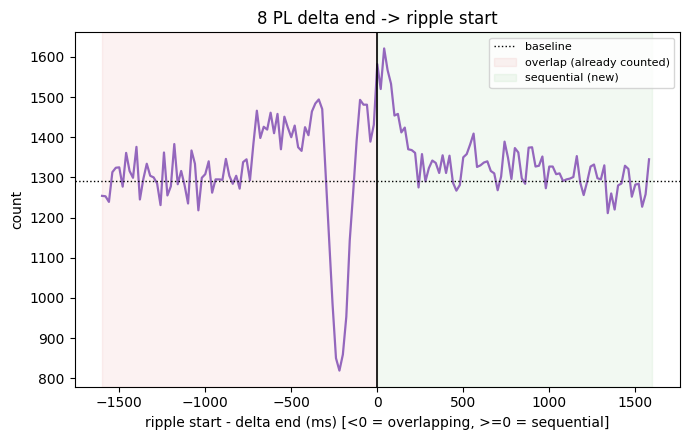

saved: 15_histogram_end_start_8_RSC


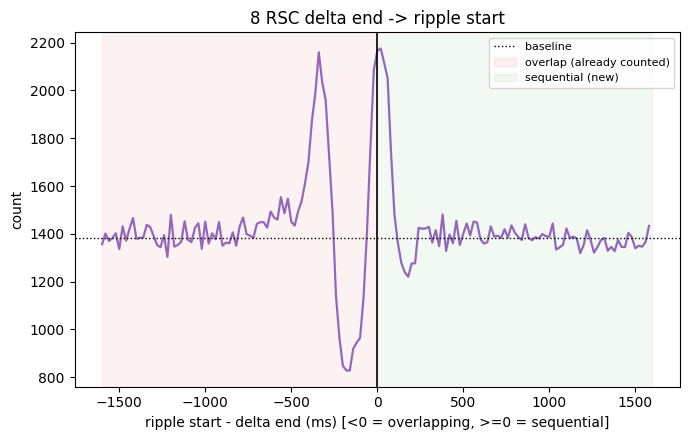

saved: 15_histogram_end_start_8_HPC


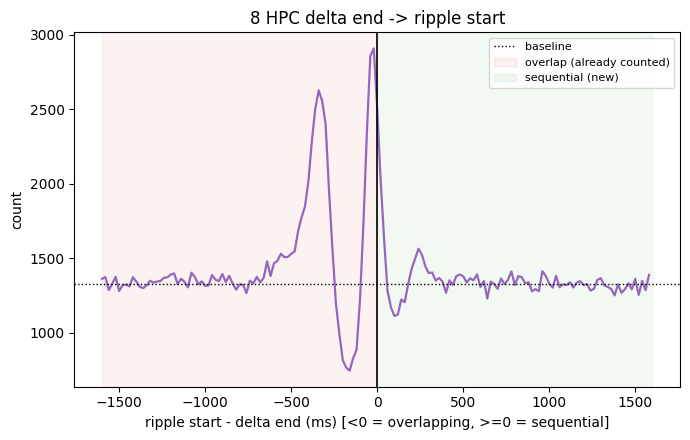

saved: 15_histogram_end_start_11_PL


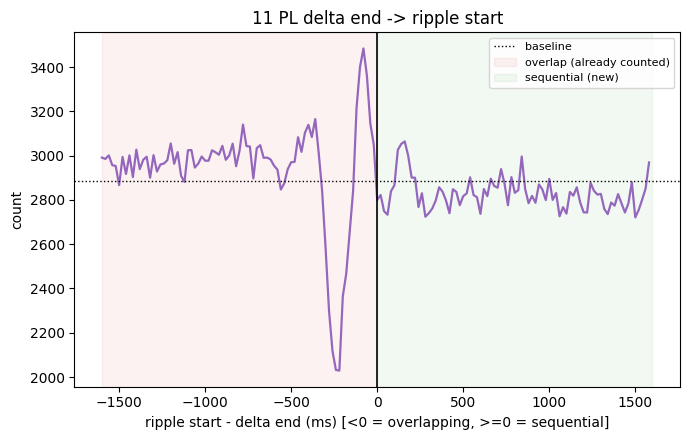

saved: 15_histogram_end_start_11_RSC


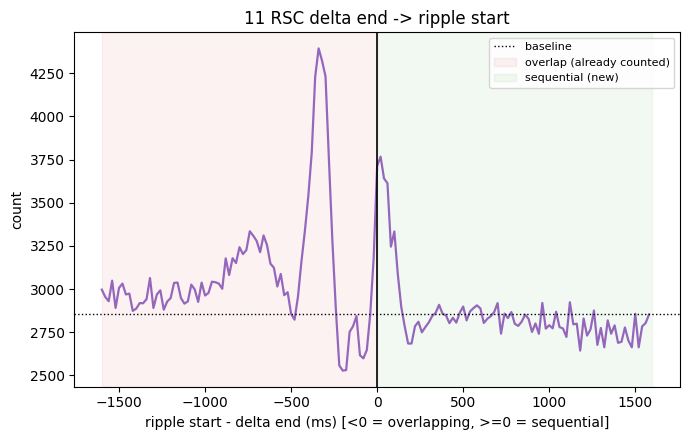

saved: 15_histogram_end_start_11_HPC


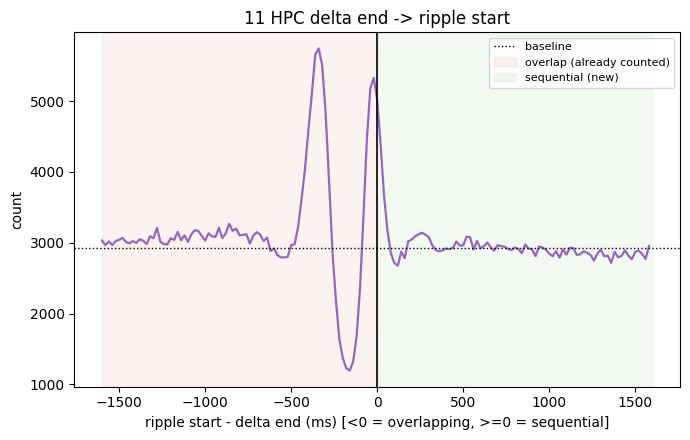

saved: 15_histogram_end_start_12_PL


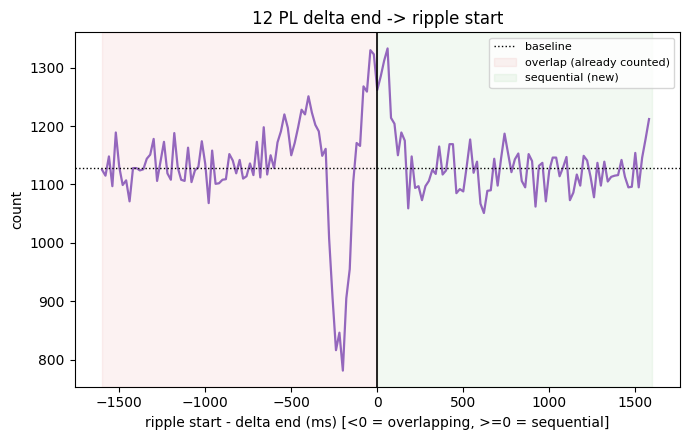

saved: 15_histogram_end_start_12_RSC


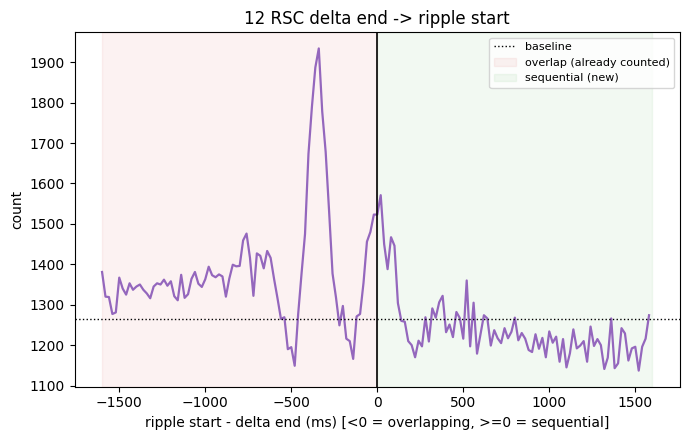

saved: 15_histogram_end_start_12_HPC


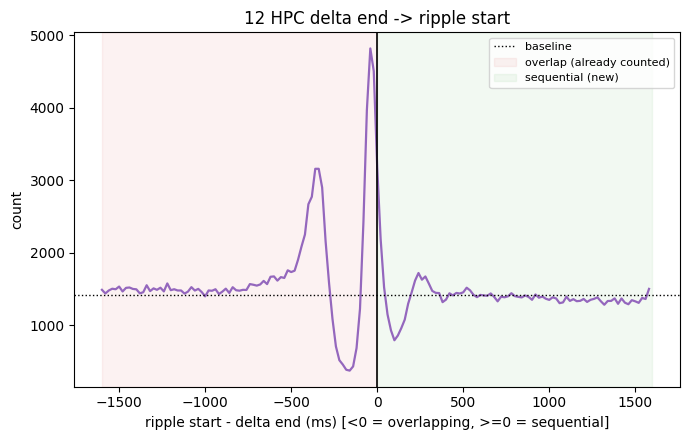

In [37]:
for rat, area_results in res_end_start_dr_by_rat.items():

    for area, r in area_results.items():

        fig, ax = plt.subplots(figsize=(7, 4.5))

        ax.plot(
            left_es, r["counts"],
            color="tab:purple", lw=1.6
        )

        ax.axhline(
            r["baseline"],
            color="k", lw=1, ls=":",
            label="baseline"
        )

        ax.axvline(0, color="k", lw=1.2)

        ax.axvspan(
            EDGES_ES[0], 0,
            color="tab:red", alpha=0.06,
            label="overlap (already counted)"
        )

        ax.axvspan(
            0, EDGES_ES[-1],
            color="tab:green", alpha=0.06,
            label="sequential (new)"
        )

        ax.set_xlabel(
            "ripple start - delta end (ms) "
            "[<0 = overlapping, >=0 = sequential]"
        )

        ax.set_ylabel("count")

        ax.set_title(
            f"{rat} {area} delta end -> ripple start"
        )

        ax.legend(fontsize=8)

        plt.tight_layout()

        save_fig(
            fig,
            f"15_histogram_end_start_{rat}_{area}"
        )

        plt.show()

# Delta phase (Hilbert transform), not run yet

Is ripple timing locked to the phase of the ongoing delta rhythm?

Continuous LFP band-pass filtered, then Hilbert transform for phase.

Delta band 0.5-4 Hz (confirmed with Yixiao). The LFP is read one trial file at a time from `PreprocessedData` (peak indices are within-trial), on the channel the delta waves were detected on.

In [30]:
import io
import shutil
import time as _time

import scipy.io
from scipy.signal import butter, hilbert, sosfiltfilt

FS_HZ = 1000.0  # 1 sample = 1 ms
DELTA_BAND = (0.5, 4.0)  # Hz (confirmed with Yixiao)

# ROOT / Rat_HM_Ephys_TD_Analysis_R1_8-or-R9_16 / <rat-group> / PreprocessedData /
#   <area> / <rat> / <date> / <phase> / chan<channel>_<trial>.mat   (unsplit days: chan<channel>.mat)
ANALYSIS_GROUPS = {
    "Rat_HM_Ephys_TD_Analysis_R1_8": ["R1-4", "R5-8"],
    "Rat_HM_Ephys_TD_Analysis_R9_16": ["R9-12", "R13-16"],
}


def _find_preproc_rat_dir(area, rat):
    """PreprocessedData/<area>/<rat>, trying every ANALYSIS_GROUPS folder."""
    for analysis, subgroups in ANALYSIS_GROUPS.items():
        for sub in subgroups:
            cand = ROOT / analysis / sub / "PreprocessedData" / area / str(rat)
            if cand.exists():
                return cand
    return None


def channel_for(delta_df, rat, area, date):
    """Recording channel of this rat/area/date's delta detection (from the event table)."""
    rows = delta_df[
        (delta_df["rat"] == rat)
        & (delta_df["area"] == area)
        & (delta_df["date"] == date)
    ]
    chans = rows["channel"].dropna().unique()
    if len(chans) == 0:
        return None
    if len(chans) > 1:
        print(
            f"    warning: rat {rat} {area} {pd.Timestamp(date).date()} has "
            f"several channels {list(chans)}, using {chans[0]}"
        )
    return int(chans[0])


class UnreadableMatFile(FileNotFoundError):
    """The .mat file exists but could not be read (network / drive problem)."""


unreadable_lfp = []  # files skipped after all retries


def _load_mat_signal(
    path, chunk_bytes=8 * 1024 * 1024, attempts=6, waits=(10, 20, 30, 40, 60)
):
    """'data' array of one .mat file. Reading straight off Z: with loadmat(path)
    failed with OSError [Errno 22] part-way through a file, so the file is copied
    into memory in 8 MB pieces first, and a failed read is retried."""
    last = None
    for attempt in range(1, attempts + 1):
        try:
            buf = io.BytesIO()
            with open(path, "rb") as f:
                shutil.copyfileobj(f, buf, chunk_bytes)
            buf.seek(0)
            return scipy.io.loadmat(buf)["data"].squeeze()
        except OSError as e:
            last = e
            if attempt < attempts:
                _time.sleep(waits[min(attempt - 1, len(waits) - 1)])
    raise UnreadableMatFile(f"{path} unreadable after {attempts} attempts: {last}")


def load_trial_lfp(rat, date, trial, area, channel, phase="postsleep"):
    """LFP of one trial ('data' in chan<channel>_<trial>.mat, or chan<channel>.mat
    for unsplit days). None if the file isn't there."""
    rat_dir = _find_preproc_rat_dir(area, rat)
    if rat_dir is None:
        return None
    phase_dir = rat_dir / pd.to_datetime(date).strftime("%Y%m%d") / phase
    for f in (
        phase_dir / f"chan{channel}_{int(trial)}.mat",
        phase_dir / f"chan{channel}.mat",
    ):
        if f.exists():
            try:
                return _load_mat_signal(f).ravel()
            except UnreadableMatFile as e:
                unreadable_lfp.append(str(e))
                return None
    return None


def bandpass_delta(signal, fs=FS_HZ, band=DELTA_BAND, order=4):
    """Zero-phase Butterworth band-pass into the delta band. Second-order sections:
    the (b, a) form of this filter is unstable at 1000 Hz (output blows up)."""
    sos = butter(order, band, btype="band", fs=fs, output="sos")
    return sosfiltfilt(sos, signal)


def delta_phase_at_times(signal, fs, event_sample_indices):
    """Delta phase (radians, -pi..pi) at each sample index; NaN outside the trace."""
    phase = np.angle(hilbert(bandpass_delta(signal, fs=fs)))
    out = np.full(len(event_sample_indices), np.nan)
    ok = (event_sample_indices >= 0) & (event_sample_indices < len(phase))
    out[ok] = phase[event_sample_indices[ok]]
    return out


def event_phases(ev_df, peak_col, area, delta_df):
    """Delta phase in `area` at every event peak, one trial file at a time
    (peak indices are within-trial sample indices)."""
    out = []
    for (rat, date, trial), g in ev_df.groupby(["rat", "date", "trial"]):
        channel = channel_for(delta_df, rat, area, date)
        if channel is None:
            continue
        sig = load_trial_lfp(rat, date, trial, area, channel)
        if sig is None:
            continue
        peaks = g[peak_col].dropna().to_numpy().astype(int)
        if len(peaks):
            out.append(delta_phase_at_times(sig, FS_HZ, peaks))
    ph = np.concatenate(out) if out else np.array([])
    return ph[~np.isnan(ph)]


def event_phase_diffs(ev_df, peak_col, area_a, area_b, delta_df):
    """Delta phase difference area_a - area_b (wrapped to -pi..pi) at every event peak."""
    out = []
    for (rat, date, trial), g in ev_df.groupby(["rat", "date", "trial"]):
        ch_a = channel_for(delta_df, rat, area_a, date)
        ch_b = channel_for(delta_df, rat, area_b, date)
        if ch_a is None or ch_b is None:
            continue
        sig_a = load_trial_lfp(rat, date, trial, area_a, ch_a)
        sig_b = load_trial_lfp(rat, date, trial, area_b, ch_b)
        if sig_a is None or sig_b is None:
            continue
        peaks = g[peak_col].dropna().to_numpy().astype(int)
        if len(peaks):
            d = delta_phase_at_times(sig_a, FS_HZ, peaks) - delta_phase_at_times(
                sig_b, FS_HZ, peaks
            )
            out.append((d[~np.isnan(d)] + np.pi) % (2 * np.pi) - np.pi)
    return np.concatenate(out) if out else np.array([])

In [39]:
def rayleigh_test(phases):
    """Rayleigh test for non-uniformity of a circular distribution.

    Returns (R, z, p). Standard large-sample approximation
    (Zar, Biostatistical Analysis): z = n*R^2, p = exp(-z) * (1 + (2z -
    z^2) / (4n) - ...), using the common two-term correction. Valid for
    n > ~10; for smaller samples treat the p-value as approximate.
    """
    n = len(phases)
    if n == 0:
        return np.nan, np.nan, np.nan
    C = np.sum(np.cos(phases))
    S = np.sum(np.sin(phases))
    R = np.sqrt(C**2 + S**2) / n
    z = n * R**2
    p = np.exp(-z) * (
        1
        + (2 * z - z**2) / (4 * n)
        - (24 * z - 132 * z**2 + 76 * z**3 - 9 * z**4) / (288 * n**2)
    )
    return R, z, max(min(p, 1.0), 0.0)


def circular_hist(ax, phases, bins=24, color="tab:purple"):
    """Phase histogram on a polar axis."""
    counts, edges = np.histogram(phases, bins=bins, range=(-np.pi, np.pi))
    width = edges[1] - edges[0]
    ax.bar(
        edges[:-1],
        counts,
        width=width,
        align="edge",
        color=color,
        alpha=0.75,
        edgecolor="white",
    )
    ax.set_theta_zero_location("N")
    ax.set_theta_direction(-1)


# delta phase at each ripple peak, per delta area
phase_by_area = {}
for area in AREAS:
    phase_by_area[area] = event_phases(rip_ctx, "ripple_peak_index", area, dlt_ctx)
    print(f"{area}: {len(phase_by_area[area])} ripple-phase samples collected")

PL: 515364 ripple-phase samples collected
RSC: 515364 ripple-phase samples collected
HPC: 515364 ripple-phase samples collected


saved: 16_delta_phase_per_area


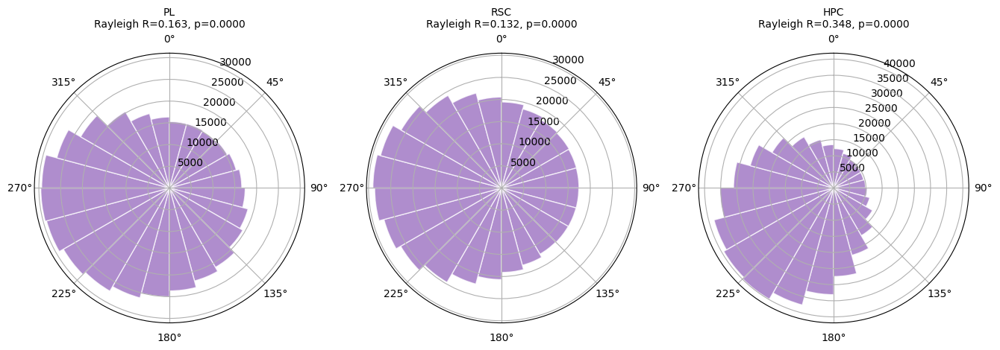

In [40]:
# circular histogram + Rayleigh test per area
fig, axes = plt.subplots(
    1, len(AREAS), figsize=(4.5 * len(AREAS), 4.5), subplot_kw={"projection": "polar"}
)
axes = np.atleast_1d(axes)
for ax, area in zip(axes, AREAS):
    phases = phase_by_area[area]
    circular_hist(ax, phases)
    if len(phases):
        R, z, p = rayleigh_test(phases)
        ax.set_title(f"{area}\nRayleigh R={R:.3f}, p={p:.4f}", fontsize=10)
    else:
        ax.set_title(f"{area}\n(no data yet)", fontsize=10)
plt.tight_layout()
save_fig(fig, "16_delta_phase_per_area")
plt.show()

In [41]:
# Delta phase at ripple peak — per rat, per area

RAT_COL = "rat"

phase_by_rat_area = {}

rats = sorted(
    set(dlt_ctx[RAT_COL].dropna().unique())
    & set(rip_ctx[RAT_COL].dropna().unique()),
    key=str
)

for rat in rats:

    phase_by_rat_area[rat] = {}

    # Select data from this rat only
    rip_rat = rip_ctx[rip_ctx[RAT_COL] == rat]
    dlt_rat = dlt_ctx[dlt_ctx[RAT_COL] == rat]

    for area in AREAS:

        phases = event_phases(
            rip_rat,
            "ripple_peak_index",
            area,
            dlt_rat
        )

        phases = np.asarray(phases)
        phases = phases[np.isfinite(phases)]

        phase_by_rat_area[rat][area] = phases

        print(
            f"{rat} | {area}: "
            f"{len(phases)} ripple-phase samples"
        )

1 | PL: 41474 ripple-phase samples
1 | RSC: 41474 ripple-phase samples
1 | HPC: 41474 ripple-phase samples
11 | PL: 145004 ripple-phase samples
11 | RSC: 145004 ripple-phase samples
11 | HPC: 145004 ripple-phase samples
12 | PL: 64328 ripple-phase samples
12 | RSC: 64328 ripple-phase samples
12 | HPC: 64328 ripple-phase samples
13 | PL: 87534 ripple-phase samples
13 | RSC: 87534 ripple-phase samples
13 | HPC: 87534 ripple-phase samples
3 | PL: 81753 ripple-phase samples
3 | RSC: 81753 ripple-phase samples
3 | HPC: 81753 ripple-phase samples
7 | PL: 34580 ripple-phase samples
7 | RSC: 34580 ripple-phase samples
7 | HPC: 34580 ripple-phase samples
8 | PL: 60691 ripple-phase samples
8 | RSC: 60691 ripple-phase samples
8 | HPC: 60691 ripple-phase samples


saved: 16_delta_phase_1


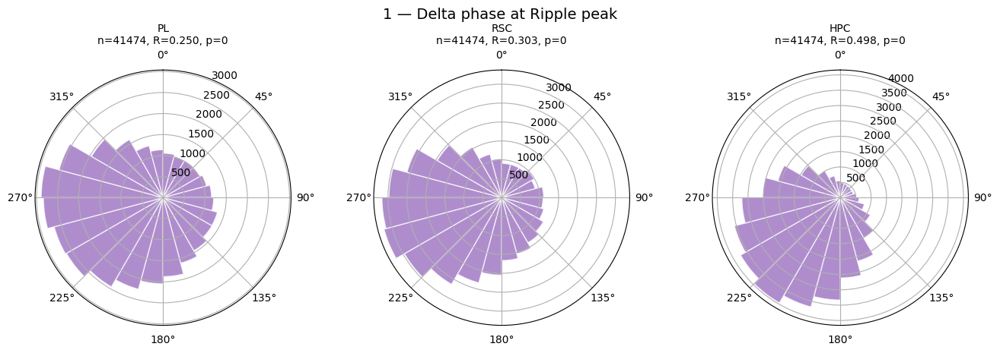

saved: 16_delta_phase_11


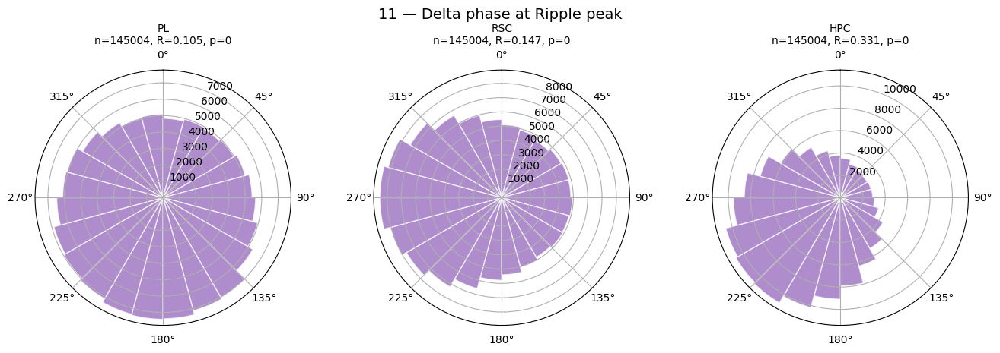

saved: 16_delta_phase_12


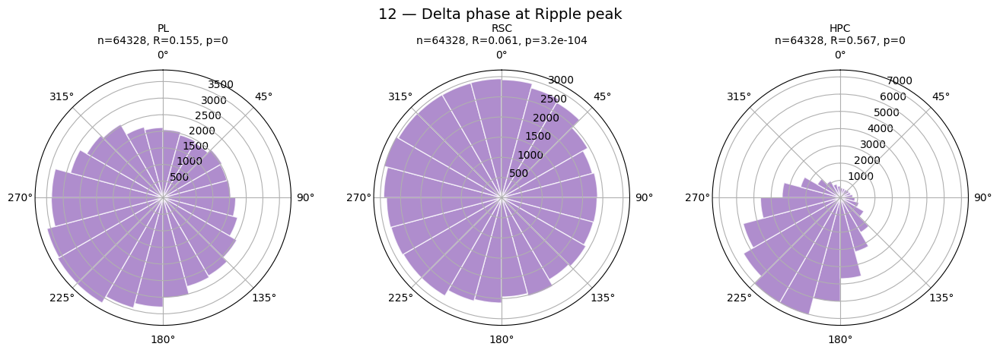

saved: 16_delta_phase_13


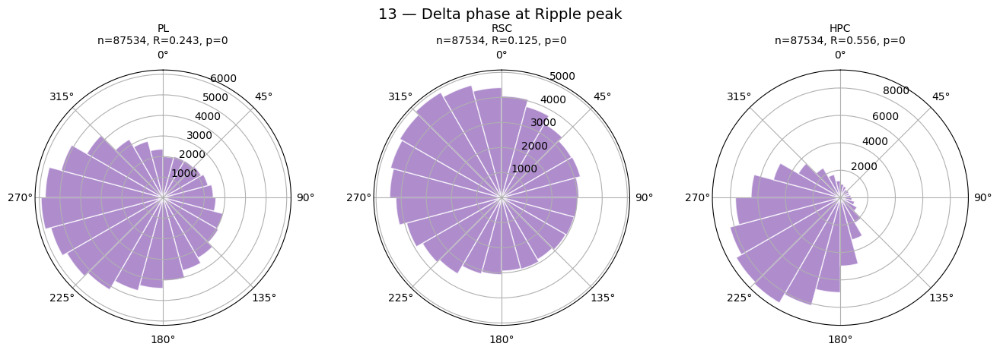

saved: 16_delta_phase_3


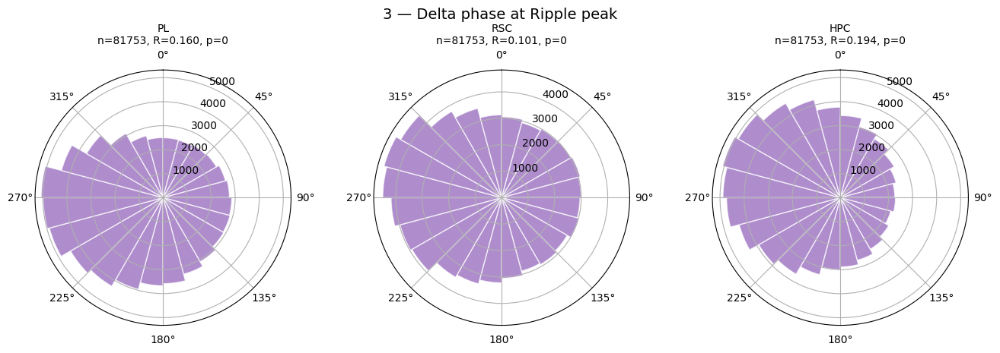

saved: 16_delta_phase_7


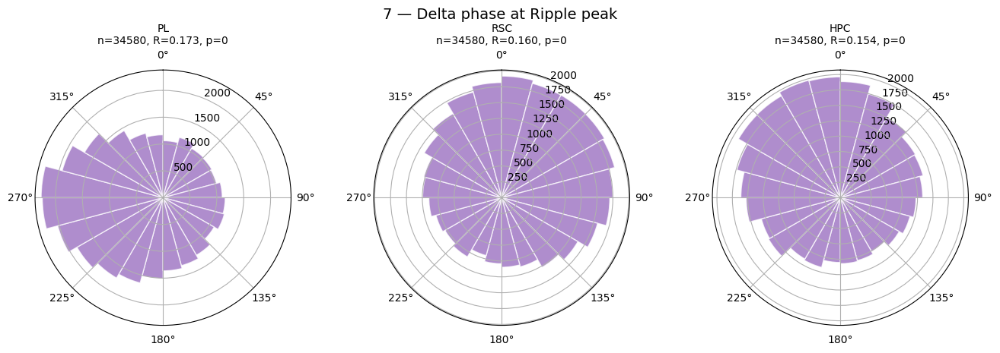

saved: 16_delta_phase_8


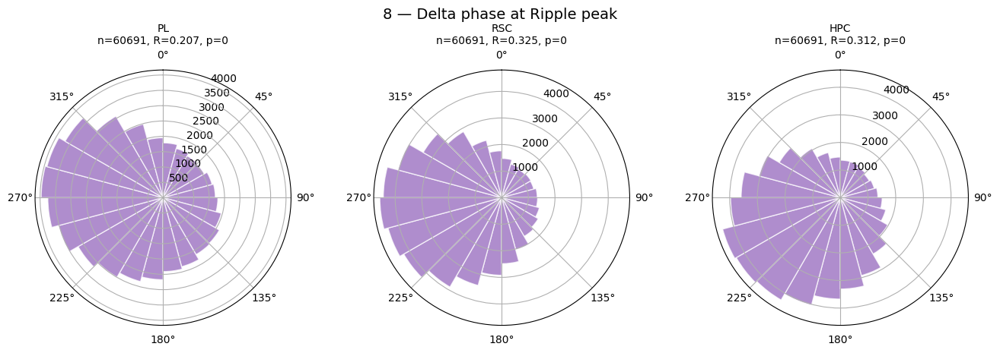

In [42]:
# Per-rat Delta–Ripple phase histograms

for rat, area_results in phase_by_rat_area.items():

    fig, axes = plt.subplots(
        1,
        len(AREAS),
        figsize=(4.5 * len(AREAS), 4.5),
        subplot_kw={"projection": "polar"}
    )

    axes = np.atleast_1d(axes)

    for ax, area in zip(axes, AREAS):

        phases = area_results[area]

        if len(phases) > 0:

            circular_hist(
                ax,
                phases,
                bins=24,
                color="tab:purple"
            )

            R, z, p = rayleigh_test(phases)

            ax.set_title(
                f"{area}\n"
                f"n={len(phases)}, R={R:.3f}, p={p:.2g}",
                fontsize=10
            )

        else:
            ax.set_title(
                f"{area}\n(no data)",
                fontsize=10
            )

    fig.suptitle(
        f"{rat} — Delta phase at Ripple peak",
        fontsize=14
    )

    plt.tight_layout()

    save_fig(
        fig,
        f"16_delta_phase_{rat}"
    )

    plt.show()

In [43]:
# Ripple peak position within DETECTED delta events only

import numpy as np
import pandas as pd

START_COL = "delta_start_index"  # first trough
PEAK_COL = "delta_peak_index"
END_COL = "delta_end_index"
RIP_COL = "ripple_peak_index"

keys = ["rat", "date", "trial"]

ripple_groups = {
    key: g
    for key, g in rip_ctx.groupby(keys)
}

results = []

for (rat, date, trial, area), delta_group in dlt_ctx.groupby(
    keys + ["area"]
):

    rip_group = ripple_groups.get((rat, date, trial))

    if rip_group is None:
        continue

    ripple_peaks = np.sort(
        rip_group[RIP_COL].dropna().to_numpy(dtype=int)
    )

    for _, delta in delta_group.iterrows():

        if delta[[START_COL, PEAK_COL, END_COL]].isna().any():
            continue

        t1 = int(delta[START_COL])
        tp = int(delta[PEAK_COL])
        t2 = int(delta[END_COL])

        if not (t1 < tp < t2):
            continue

        # Ripple peaks inside this detected delta event
        i0 = np.searchsorted(ripple_peaks, t1, side="left")
        i1 = np.searchsorted(ripple_peaks, t2, side="right")

        for tr in ripple_peaks[i0:i1]:

            # Event-relative phase
            if tr <= tp:
                phase = 180 * (tr - t1) / (tp - t1)
                segment = "rising"
            else:
                phase = 180 + 180 * (tr - tp) / (t2 - tp)
                segment = "falling"

            results.append({
                "rat": rat,
                "date": date,
                "trial": trial,
                "area": area,
                "ripple_peak_index": tr,
                "delta_peak_index": tp,
                "phase_deg": phase,
                "segment": segment,
                "distance_to_peak_ms": abs(tr - tp)
            })

event_phase_df = pd.DataFrame(results)

# If delta events overlap, assign a ripple to the
# delta event with the closest peak, per area.
if not event_phase_df.empty:
    event_phase_df = (
        event_phase_df
        .sort_values("distance_to_peak_ms")
        .drop_duplicates(
            subset=keys + ["area", "ripple_peak_index"]
        )
        .reset_index(drop=True)
    )

display(event_phase_df)

,rat,date,trial,area,ripple_peak_index,delta_peak_index,phase_deg,segment,distance_to_peak_ms
0,11,2023-07-11,12,HPC,252970,252970,180.000000,rising,0
1,12,2023-08-23,11,RSC,700659,700659,180.000000,rising,0
2,11,2023-07-25,10,RSC,1312078,1312078,180.000000,rising,0
3,11,2023-08-16,8,RSC,1781971,1781971,180.000000,rising,0
4,3,2022-11-22,8,RSC,1207887,1207887,180.000000,rising,0
...,...,...,...,...,...,...,...,...,...
720004,12,2023-08-08,8,PL,849244,849935,40.560538,rising,691
720005,3,2022-10-21,10,PL,437006,437699,27.506112,rising,693
720006,11,2023-07-26,6,PL,1078243,1078956,6.801619,rising,713
720007,11,2023-07-26,6,HPC,1078243,1078962,6.048387,rising,719


saved: 17_ripple_delta_event_phase_rat_1


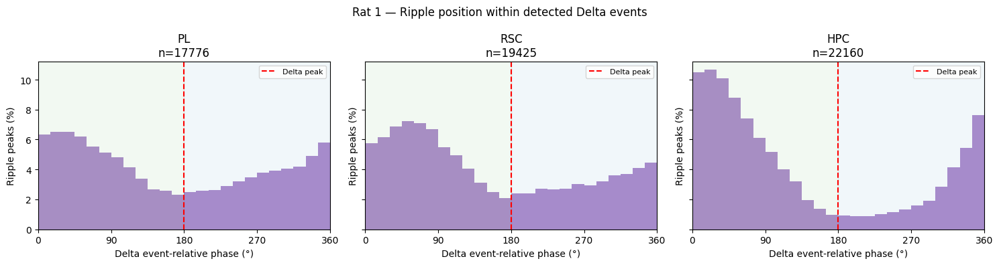

saved: 17_ripple_delta_event_phase_rat_3


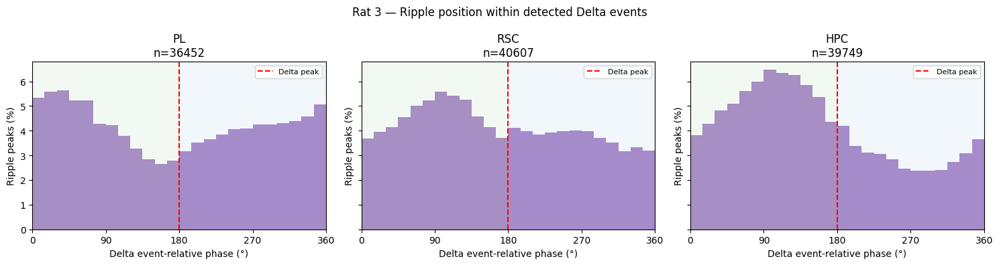

saved: 17_ripple_delta_event_phase_rat_7


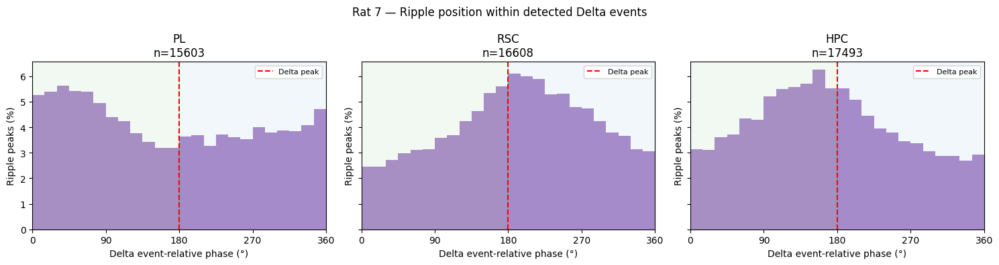

saved: 17_ripple_delta_event_phase_rat_8


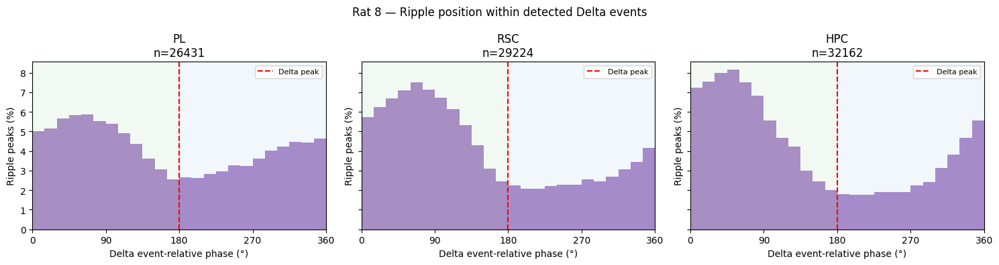

saved: 17_ripple_delta_event_phase_rat_11


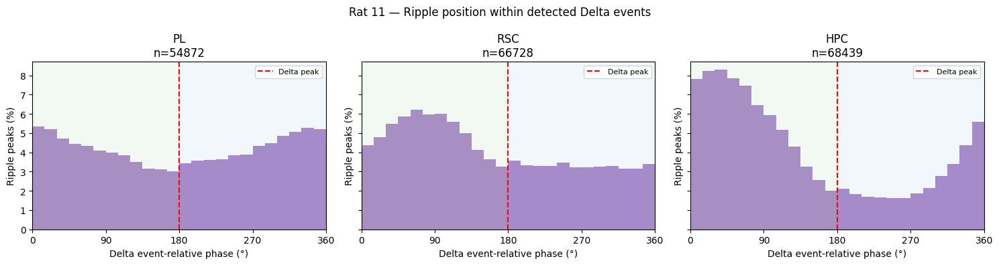

saved: 17_ripple_delta_event_phase_rat_12


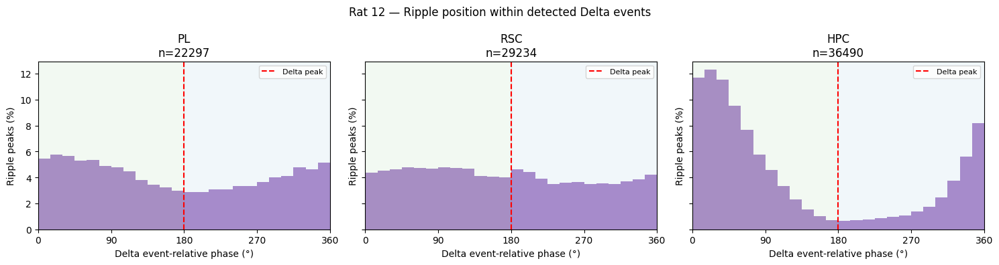

saved: 17_ripple_delta_event_phase_rat_13


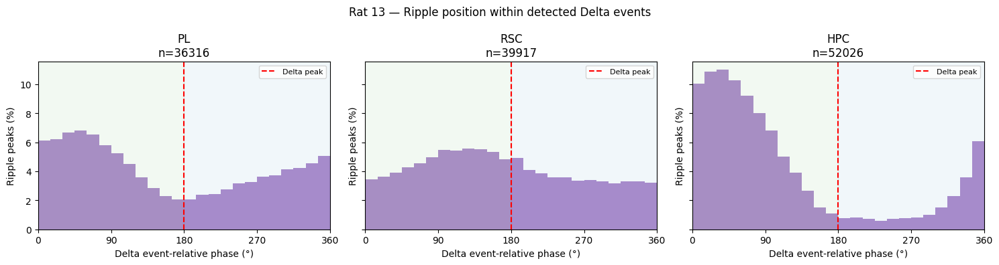

In [44]:
for rat in sorted(event_phase_df["rat"].unique()):

    fig, axes = plt.subplots(
        1, len(AREAS),
        figsize=(5 * len(AREAS), 4),
        sharey=True
    )

    axes = np.atleast_1d(axes)

    for ax, area in zip(axes, AREAS):

        phases = event_phase_df.loc[
            (event_phase_df["rat"] == rat)
            & (event_phase_df["area"] == area),
            "phase_deg"
        ].to_numpy()

        if len(phases) == 0:
            ax.set_title(f"{area}\nNo data")
            continue

        counts, edges = np.histogram(
            phases,
            bins=np.arange(0, 361, 15)
        )

        percentage = counts / counts.sum() * 100

        ax.bar(
            edges[:-1],
            percentage,
            width=15,
            align="edge",
            color="tab:purple",
            alpha=0.75
        )

        ax.axvline(
            180, color="red", ls="--",
            label="Delta peak"
        )

        ax.axvspan(
            0, 180,
            color="tab:green",
            alpha=0.06
        )

        ax.axvspan(
            180, 360,
            color="tab:blue",
            alpha=0.06
        )

        ax.set_xlim(0, 360)
        ax.set_xticks([0, 90, 180, 270, 360])

        ax.set_xlabel("Delta event-relative phase (°)")
        ax.set_ylabel("Ripple peaks (%)")

        ax.set_title(
            f"{area}\n"
            f"n={len(phases)}"
        )

        ax.legend(fontsize=8)

    fig.suptitle(
        f"Rat {rat} — Ripple position within detected Delta events"
    )

    plt.tight_layout()
    save_fig(fig, f"17_ripple_delta_event_phase_rat_{rat}")
    plt.show()

saved: 17_ripple_delta_phase_overall


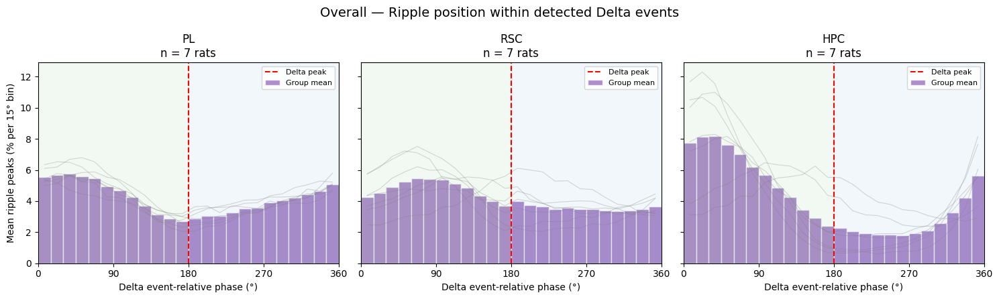

saved: 17_ripple_delta_phase_build_up_phase


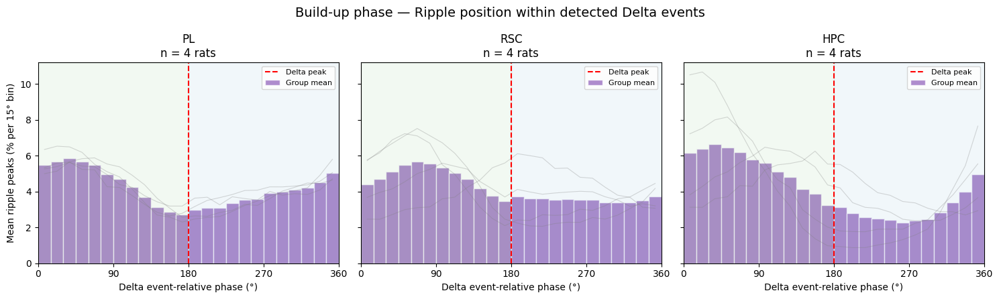

saved: 17_ripple_delta_phase_update_phase


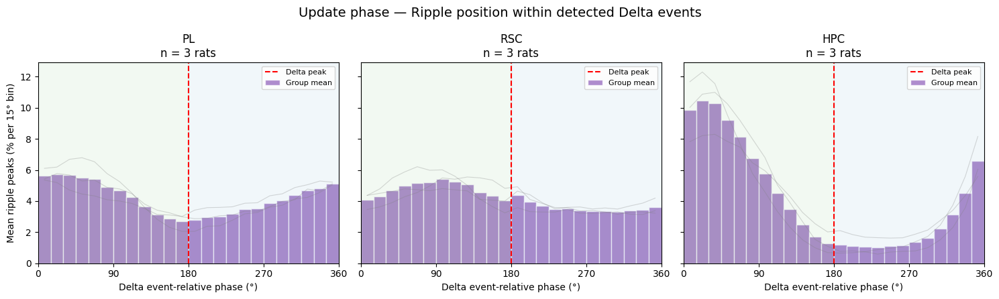

In [46]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---------------------------------------
# Group definitions
# ---------------------------------------

GROUPS = {
    "Overall": [1, 3, 7, 8, 11, 12, 13],
    "Build-up phase": [1, 3, 7, 8],
    "Update phase": [11, 12, 13],
}

# Make sure rat IDs are numeric
df = event_phase_df.copy()

df["rat_id"] = pd.to_numeric(
    df["rat"].astype(str).str.extract(r"(\d+)", expand=False),
    errors="coerce"
)

# 15-degree bins
edges = np.arange(0, 361, 15)
centers = (edges[:-1] + edges[1:]) / 2

# ---------------------------------------
# Plot group-average histograms
# ---------------------------------------

for group_name, rat_list in GROUPS.items():

    fig, axes = plt.subplots(
        1,
        len(AREAS),
        figsize=(5 * len(AREAS), 4.5),
        sharey=True
    )

    axes = np.atleast_1d(axes)

    for ax, area in zip(axes, AREAS):

        rat_percentages = []

        for rat in rat_list:

            phases = df.loc[
                (df["rat_id"] == rat)
                & (df["area"] == area),
                "phase_deg"
            ].to_numpy(dtype=float)

            phases = phases[
                np.isfinite(phases)
                & (phases >= 0)
                & (phases <= 360)
            ]

            if len(phases) == 0:
                continue

            # Histogram for this rat
            counts, _ = np.histogram(
                phases,
                bins=edges
            )

            # Convert to percentage
            pct = counts / counts.sum() * 100

            rat_percentages.append(pct)

        if len(rat_percentages) == 0:
            ax.set_title(f"{area}\nNo data")
            continue

        rat_percentages = np.array(rat_percentages)

        # Average percentage across rats
        mean_pct = np.mean(rat_percentages, axis=0)

        # Individual rats (light gray lines)
        for pct in rat_percentages:
            ax.plot(
                centers,
                pct,
                color="gray",
                lw=0.8,
                alpha=0.3
            )

        # Group mean histogram
        ax.bar(
            edges[:-1],
            mean_pct,
            width=15,
            align="edge",
            color="tab:purple",
            alpha=0.75,
            edgecolor="white",
            label="Group mean"
        )

        # Delta peak
        ax.axvline(
            180,
            color="red",
            ls="--",
            lw=1.5,
            label="Delta peak"
        )

        # Rising phase
        ax.axvspan(
            0, 180,
            color="tab:green",
            alpha=0.06
        )

        # Falling phase
        ax.axvspan(
            180, 360,
            color="tab:blue",
            alpha=0.06
        )

        ax.set_xlim(0, 360)
        ax.set_xticks([0, 90, 180, 270, 360])

        ax.set_xlabel(
            "Delta event-relative phase (°)"
        )

        ax.set_title(
            f"{area}\n"
            f"n = {len(rat_percentages)} rats"
        )

        ax.legend(fontsize=8)

    axes[0].set_ylabel(
        "Mean ripple peaks (% per 15° bin)"
    )

    fig.suptitle(
        f"{group_name} — Ripple position within detected Delta events",
        fontsize=14
    )

    plt.tight_layout()

    save_name = (
        group_name.lower()
        .replace(" ", "_")
        .replace("-", "_")
    )

    save_fig(
        fig,
        f"17_ripple_delta_phase_{save_name}"
    )

    plt.show()

In [70]:
# phase difference between two areas at each ripple peak (wrapped to -pi..pi)
from itertools import combinations

cross_area_diffs = {}
for area_a, area_b in combinations(AREAS, 2):
    cross_area_diffs[(area_a, area_b)] = event_phase_diffs(
        rip_ctx, "ripple_peak_index", area_a, area_b, dlt_ctx
    )

if unreadable_lfp:
    print(f"{len(unreadable_lfp)} LFP files could not be read and were skipped:")
    for msg in unreadable_lfp:
        print("   ", msg)

fig, axes = plt.subplots(
    1,
    len(cross_area_diffs),
    figsize=(4.5 * len(cross_area_diffs), 4.5),
    subplot_kw={"projection": "polar"},
)
axes = np.atleast_1d(axes)
for ax, (pair, diffs) in zip(axes, cross_area_diffs.items()):
    circular_hist(ax, diffs, color="tab:teal")
    if len(diffs):
        R, z, p = rayleigh_test(diffs)
        ax.set_title(f"{pair[0]}-{pair[1]}\nRayleigh R={R:.3f}, p={p:.4f}", fontsize=9)
    else:
        ax.set_title(f"{pair[0]}-{pair[1]}\n(no data yet)", fontsize=9)
plt.tight_layout()
save_fig(fig, "17_cross_area_delta_phase_diff")
plt.show()

KeyboardInterrupt: 

# Can each day be trusted?

## Circular shift per recording day

Shifts the ripple train within each recording's NREM time and recomputes the window count. Keeps ripple timing, removes alignment with delta.

All seven rats. Use the z-score, p can't go below 1/N_ITER.

The loop below was rewritten from the description in `Corrected_Task2_OverTime.ipynb` (the original cell was missing).

In [ ]:
CACHE_PERDAY = OUT / "perday_shift_cache"
CACHE_PERDAY.mkdir(parents=True, exist_ok=True)


def per_day_shift_zscores(dlt_df, rip_df, area, rats, n_iter=N_ITER, seed=0):
    """Per-day circular-shift test: for each rat-day, shift the ripple train
    within its own recording (scope="recording") and compare the observed
    R->D / D->R window counts against that day's own shuffled null.

    z_window : how many SDs the observed R->D count sits above this day's own
               null, averaged across the 50-250 ms window -- the number that
               matters for reading per-day significance.
    z_tail   : same average, but over the far tails (beyond +/-800 ms) where
               no coupling is expected -- should sit near zero; if it does
               not, the null itself is miscalibrated for that day.

    Cached per area so an interrupted run can resume without redoing days
    already computed.
    """
    cache_f = CACHE_PERDAY / f"zscores_{area}_n{n_iter}.csv"
    if cache_f.exists():
        return pd.read_csv(cache_f, parse_dates=["date"])

    d_area = dlt_df[dlt_df["area"] == area]
    left_ = edges[:-1]
    win_rd = (left_ >= -250) & (left_ < -50)
    win_dr = (left_ >= 50) & (left_ < 400)
    tail = (left_ < -800) | (left_ >= 800)

    rows = []
    for rat in rats:
        d_rat = d_area[d_area["rat"] == rat]
        r_rat = rip_df[rip_df["rat"] == rat]
        for date, dg in d_rat.groupby("date"):
            rg = r_rat[r_rat["date"] == date]
            if rg.empty or dg.empty:
                continue
            dist = sg.surrogate_distribution(
                dg,
                rg,
                "delta",
                "ripple",
                edges,
                n_iter=n_iter,
                seed=seed,
                scope="recording",
                verbose=False,
            )
            rows.append(
                {
                    "rat": rat,
                    "date": date,
                    "area": area,
                    "z_window_RD": float(np.nanmean(dist["z"][win_rd])),
                    "z_window_DR": float(np.nanmean(dist["z"][win_dr])),
                    "z_tail": float(np.nanmean(dist["z"][tail])),
                    "n_bouts": dist["n_bouts"],
                }
            )
    out = pd.DataFrame(rows)
    out.to_csv(cache_f, index=False)
    return out


perday_z = pd.concat(
    [per_day_shift_zscores(dlt_ctx, rip_ctx, area, SHIFT_RATS) for area in AREAS],
    ignore_index=True,
)
print(f"{len(perday_z)} rat-day-area z-scores computed")
print("z_tail (should sit near zero -- the null-calibration check):")
print(perday_z.groupby("area")["z_tail"].agg(["mean", "std"]).round(3).to_string())

## Per-day significance plots

`z_window_RD` = observed R->D count vs the day's null, in SDs. Around 2 or lower = not different from chance on that day.

In [ ]:
fig, axes = plt.subplots(1, len(AREAS), figsize=(4.8 * len(AREAS), 4), sharey=True)
axes = np.atleast_1d(axes)
for ax, area in zip(axes, AREAS):
    z = perday_z[perday_z["area"] == area]["z_window_RD"].dropna()
    ax.hist(z, bins=30, color="tab:blue", alpha=0.75)
    ax.axvline(2, color="k", lw=1, ls=":", label="z = 2")
    ax.set_title(f"{area}   {int((z >= 2).sum())}/{len(z)} days z>=2")
    ax.set_xlabel("z_window_RD")
axes[0].set_ylabel("rat-days")
axes[0].legend(fontsize=8)
fig.suptitle("Per-day R->D significance, all seven rats", fontsize=12)
plt.tight_layout()
save_fig(fig, "13_perday_zwindow_hist")
plt.show()

## D->R per-day significance plots

Same for D->R (50-400 ms).

NameError: name 'perday_z' is not defined

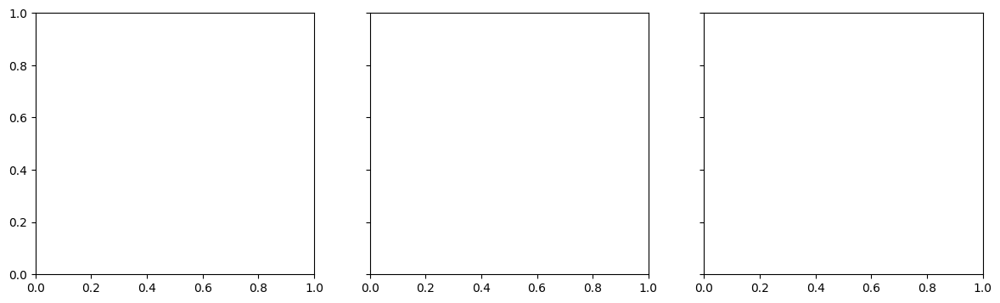

In [47]:
fig, axes = plt.subplots(1, len(AREAS), figsize=(4.8 * len(AREAS), 4), sharey=True)
axes = np.atleast_1d(axes)
for ax, area in zip(axes, AREAS):
    z = perday_z[perday_z["area"] == area]["z_window_DR"].dropna()
    ax.hist(z, bins=30, color="tab:orange", alpha=0.75)
    ax.axvline(2, color="k", lw=1, ls=":", label="z = 2")
    ax.set_title(f"{area}   {int((z >= 2).sum())}/{len(z)} days z>=2")
    ax.set_xlabel("z_window_DR")
axes[0].set_ylabel("rat-days")
axes[0].legend(fontsize=8)
fig.suptitle("Per-day D->R significance, all seven rats", fontsize=12)
plt.tight_layout()
save_fig(fig, "13b_perday_zwindow_hist_DR")
plt.show()

# NREM duration cutoff for the trend statistics

Rat-days need at least 10 min of NREM to be used in the trend statistics.

Only used for the per-rat trends below, not for the pooled histograms or the significance tests.

Also applied to every over-time plot below (trajectories, block plots, absolute counts, ripple-anchored proportions); the removed rat-days are listed in red under each plot.

In [48]:
MIN_NREM_MIN = 10  # minutes of NREM sleep required for a rat-day to count

day_nrem = (
    rip_ctx[["rat", "date", "trial", "nrem_bout_index", "nrem_bout_duration_s"]]
    .drop_duplicates(subset=["rat", "date", "trial", "nrem_bout_index"])
    .groupby(["rat", "date"])["nrem_bout_duration_s"]
    .sum()
    / 60
)
good_days = day_nrem[day_nrem >= MIN_NREM_MIN].reset_index()[["rat", "date"]]

print(
    f"rat-days: {day_nrem.shape[0]} total -> {len(good_days)} with >= {MIN_NREM_MIN} min NREM "
    f"({day_nrem.shape[0] - len(good_days)} dropped)"
)

daily_nrem = daily.merge(good_days, on=["rat", "date"])

print("rat-days remaining per area, before vs after the NREM-duration cutoff:")
before = daily.groupby("area").size()
after = daily_nrem.groupby("area").size()
print(
    pd.DataFrame(
        {"before": before, "after": after, "dropped": before - after}
    ).to_string()
)

# rat-days removed by the cutoff, listed under every plot from here on
day_group = rip_ctx[["rat", "date", "group"]].drop_duplicates(["rat", "date"])
nrem_removed = (
    day_nrem[day_nrem < MIN_NREM_MIN]
    .rename("nrem_min")
    .reset_index()
    .merge(day_group, on=["rat", "date"], how="left")
    .sort_values(["rat", "date"])
    .reset_index(drop=True)
)
print(f"removed by the NREM cutoff: {len(nrem_removed)} rat-days")


def add_nrem_footnote(fig, rats=None, groups=("HC", "Training")):
    """List the rat-days removed by the NREM cutoff under the figure."""
    rem = nrem_removed[nrem_removed["group"].isin(groups)]
    if rats is not None:
        rem = rem[rem["rat"].isin(rats)]
    if rem.empty:
        return
    parts = []
    for rat, g in rem.groupby("rat"):
        days = ", ".join(
            f"{pd.Timestamp(d).date()} {grp} ({m:.1f} min)"
            for d, grp, m in zip(g["date"], g["group"], g["nrem_min"])
        )
        parts.append(f"Rat {rat}: {days}")
    note = f"Removed, < {MIN_NREM_MIN} min NREM: " + " | ".join(parts)
    fig.text(
        0.5,
        -0.01,
        note,
        ha="center",
        va="top",
        fontsize=8,
        color="firebrick",
        wrap=True,
    )

rat-days: 186 total -> 186 with >= 10 min NREM (0 dropped)
rat-days remaining per area, before vs after the NREM-duration cutoff:
      before  after  dropped
area                        
HPC      186    186        0
PL       186    186        0
RSC      186    186        0
removed by the NREM cutoff: 0 rat-days


# Trends over time per rat

## Every recording day per rat (NREM duration filtered)

One panel per rat, x = days since first recording.

One dot per recording day. Orange = HC, blue = training, size = number of sequences.

Separate trend lines for HC and training.

Title: Spearman rho per line, * = p < 0.05.

### The numbers behind the points

In [53]:
cols = [
    "rat",
    "date",
    "days_elapsed",
    "group",
    "n_seq",
    "n_ripple",
    "nrem_min",
    "rate_RD",
    "ratio_RD",
    "prop_ripples",
    "rate_DR",
    "ratio_DR",
]
tab = (
    daily_nrem[daily_nrem["area"] == AREAS[0]]
    .assign(date=lambda d: pd.to_datetime(d["date"]).dt.strftime("%d/%m/%y"))
    .sort_values(["rat", "days_elapsed"])[cols]
)
print(f"=== {AREAS[0]} (NREM-filtered) ===")
print(tab.to_string(index=False, float_format=lambda v: f"{v:.3f}"))

print("totals per rat, all areas (NREM-filtered):")
print(
    daily_nrem.groupby(["area", "rat"])
    .agg(
        days=("date", "nunique"),
        total_seq=("n_seq", "sum"),
        median_seq=("n_seq", "median"),
    )
    .to_string()
)

=== PL (NREM-filtered) ===
 rat     date  days_elapsed    group  n_seq  n_ripple  nrem_min  rate_RD  ratio_RD  prop_ripples  rate_DR  ratio_DR
   1 23/09/22             0       HC    629      2480   111.217    5.656     1.250         0.254    7.805     0.986
   1 26/09/22             3       HC    651      2803   123.767    5.260     1.147         0.233    8.007     0.998
   1 29/09/22             6 Training    199       814    34.833    5.713     1.263         0.243    9.014     1.139
   1 03/10/22            10       HC    496      2154    93.367    5.312     1.106         0.230    8.129     0.967
   1 06/10/22            13 Training    459      1995    88.267    5.200     1.135         0.230    7.693     0.959
   1 10/10/22            17 Training    473      2037    85.233    5.549     1.188         0.232    8.494     1.039
   1 12/10/22            19 Training    421      1949    86.033    4.893     1.059         0.217    7.404     0.916
   1 13/10/22            20 Training    483  

# Trajectories and within-block view

saved: 04_blocks_ratio_RD_PL


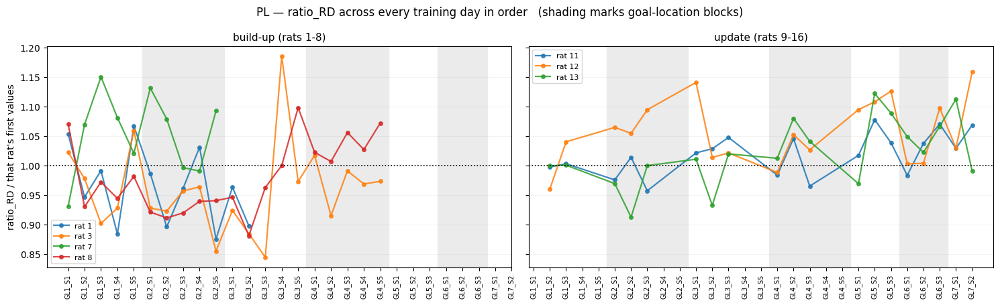

saved: 04_blocks_ratio_RD_RSC


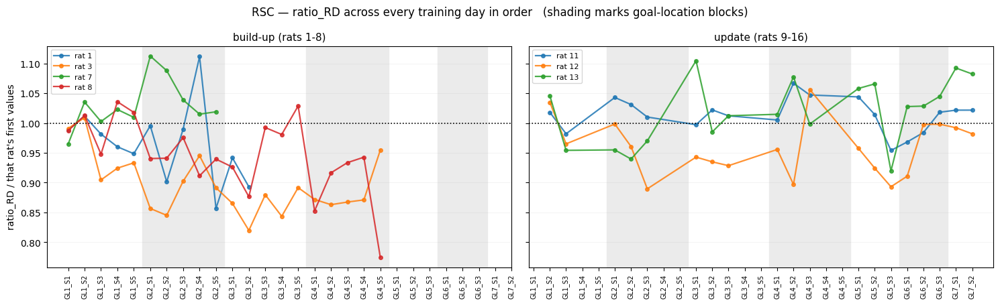

saved: 04_blocks_ratio_RD_HPC


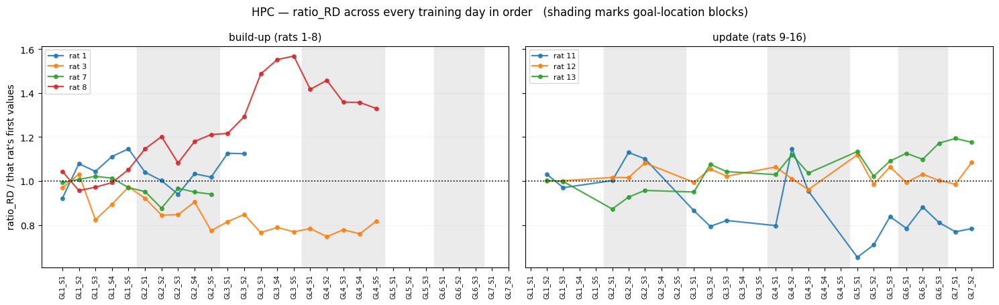

In [56]:
def block_figure(measure, area):
    """Coupling across the actual sequence of training days: GL1_S1, GL1_S2,
    ... GL2_S1, ... Nothing averaged across goal locations, so a rise within a
    block and a rise across blocks stay distinguishable."""
    sub = daily_nrem[(daily_nrem["area"] == area) & (daily_nrem["group"] == "Training")]
    sub = sub.dropna(subset=["gl_num", "session_num"])
    if sub.empty:
        return

    sub = sub.copy()
    sub["step"] = sub["gl_num"] * 10 + sub["session_num"]
    order = sorted(sub["step"].unique())
    pos = {s: i for i, s in enumerate(order)}
    labels = [f"GL{int(s // 10)}_S{int(s % 10)}" for s in order]

    fig, axes = plt.subplots(1, 2, figsize=(15, 4.6), sharey=True)
    for ax, (label, rats) in zip(axes, COHORTS.items()):
        for rat in rats:
            r = sub[sub["rat"] == rat]
            if len(r) < 3:
                continue
            g = r.groupby("step")[measure].mean()
            base = g.iloc[:2].mean()
            if base == 0 or np.isnan(base):
                continue
            ax.plot(
                [pos[s] for s in g.index],
                g.values / base,
                lw=1.6,
                alpha=0.85,
                marker="o",
                ms=4,
                label=f"rat {rat}",
            )
        for i, s in enumerate(order):
            if int(s // 10) % 2 == 0:
                ax.axvspan(i - 0.5, i + 0.5, color="0.92", zorder=0)
        ax.axhline(1, color="k", lw=1.2, ls=":")
        ax.set_xticks(range(len(labels)))
        ax.set_xticklabels(labels, rotation=90, fontsize=7)
        ax.set_title(label, fontsize=11)
        ax.legend(fontsize=8)
        ax.grid(alpha=0.2, lw=0.5, axis="y")
    axes[0].set_ylabel(f"{measure} / that rat's first values")
    fig.suptitle(
        f"{area} — {measure} across every training day in order   "
        "(shading marks goal-location blocks)",
        fontsize=12,
    )
    plt.tight_layout()
    add_nrem_footnote(fig, groups=["Training"])
    save_fig(fig, f"04_blocks_{measure}_{area}")
    plt.show()


for area in AREAS:
    block_figure("ratio_RD", area)

# Absolute-count block plots

Raw counts (not normalized), per-cohort x-axis, gaps in a rat's data left as gaps. Training days by GL block and HC days in recording order.

In [58]:
def get_shared_ylim(measure, area):
    """One y-axis range covering both GL and HC data for this area, so the
    two plots can be visually compared directly."""
    gl_vals = daily_nrem[
        (daily_nrem["area"] == area) & (daily_nrem["group"] == "Training")
    ][measure]
    hc_vals = daily_nrem[(daily_nrem["area"] == area) & (daily_nrem["group"] == "HC")][
        measure
    ]
    all_vals = pd.concat([gl_vals, hc_vals]).dropna()
    if all_vals.empty:
        return None
    pad = 0.05 * (all_vals.max() - all_vals.min())
    return (all_vals.min() - pad, all_vals.max() + pad)


def block_figure_count(measure, area, ylim=None):
    """Raw value plotted directly -- no normalization to the rat's own start."""
    sub_all = daily_nrem[
        (daily_nrem["area"] == area) & (daily_nrem["group"] == "Training")
    ]
    sub_all = sub_all.dropna(subset=["gl_num", "session_num"])
    if sub_all.empty:
        return

    fig, axes = plt.subplots(1, 2, figsize=(15, 4.6), sharey=True)
    for ax, (label, rats) in zip(axes, COHORTS.items()):
        sub = sub_all[sub_all["rat"].isin(rats)].copy()
        if sub.empty:
            ax.set_title(label, fontsize=11)
            continue

        sub["step"] = sub["gl_num"] * 10 + sub["session_num"]
        order = sorted(sub["step"].unique())
        pos = {s: i for i, s in enumerate(order)}
        labels = [f"GL{int(s // 10)}_S{int(s % 10)}" for s in order]

        for rat in rats:
            r = sub[sub["rat"] == rat]
            if len(r) < 3:
                continue
            g = r.groupby("step")[measure].mean().reindex(order)
            xs = [pos[s] for s in order]
            ax.plot(
                xs, g.values, lw=1.6, alpha=0.85, marker="o", ms=4, label=f"rat {rat}"
            )

        for i, s in enumerate(order):
            if int(s // 10) % 2 == 0:
                ax.axvspan(i - 0.5, i + 0.5, color="0.92", zorder=0)
        ax.set_xticks(range(len(labels)))
        ax.set_xticklabels(labels, rotation=90, fontsize=7)
        ax.set_title(label, fontsize=11)
        ax.legend(fontsize=8)
        ax.grid(alpha=0.2, lw=0.5, axis="y")

    axes[0].set_ylabel("absolute count")
    if ylim:
        axes[0].set_ylim(ylim)
    fig.suptitle(
        f"{area} \u2014 {measure} across every training day in order   "
        "(shading marks goal-location blocks)",
        fontsize=12,
    )
    plt.tight_layout()
    add_nrem_footnote(fig, groups=["Training"])
    save_fig(fig, f"04_blocks_{measure}_{area}")
    plt.show()


def hc_block_figure(measure, area, ylim=None):
    """HC days, per rat, in the order each rat recorded them (HC1, HC2, ...)."""
    sub_all = daily_nrem[
        (daily_nrem["area"] == area) & (daily_nrem["group"] == "HC")
    ].copy()
    if sub_all.empty:
        return

    fig, axes = plt.subplots(1, 2, figsize=(15, 4.6), sharey=True)
    for ax, (label, rats) in zip(axes, COHORTS.items()):
        sub = sub_all[sub_all["rat"].isin(rats)].copy()
        if sub.empty:
            ax.set_title(label, fontsize=11)
            continue

        max_hc = 0
        for rat in rats:
            r = sub[sub["rat"] == rat].sort_values("date")
            if len(r) < 2:
                continue
            hc_index = np.arange(1, len(r) + 1)
            max_hc = max(max_hc, len(r))
            ax.plot(
                hc_index,
                r[measure].values,
                lw=1.6,
                alpha=0.85,
                marker="o",
                ms=4,
                label=f"rat {rat}",
            )

        for i in range(1, max_hc + 1):
            if i % 2 == 0:
                ax.axvspan(i - 0.5, i + 0.5, color="0.92", zorder=0)
        ax.set_xticks(range(1, max_hc + 1))
        ax.set_xticklabels(
            [f"HC{i}" for i in range(1, max_hc + 1)], rotation=90, fontsize=7
        )
        ax.set_title(label, fontsize=11)
        ax.legend(fontsize=8)
        ax.grid(alpha=0.2, lw=0.5, axis="y")

    axes[0].set_ylabel("absolute count")
    if ylim:
        axes[0].set_ylim(ylim)
    fig.suptitle(
        f"{area} \u2014 {measure} across home-cage days, in order   "
        "(shading is cosmetic, alternating every other HC session)",
        fontsize=12,
    )
    plt.tight_layout()
    add_nrem_footnote(fig, groups=["HC"])
    save_fig(fig, f"05_hc_{measure}_{area}")
    plt.show()

## R->D, absolute count

saved: 04_blocks_n_seq_RD_PL


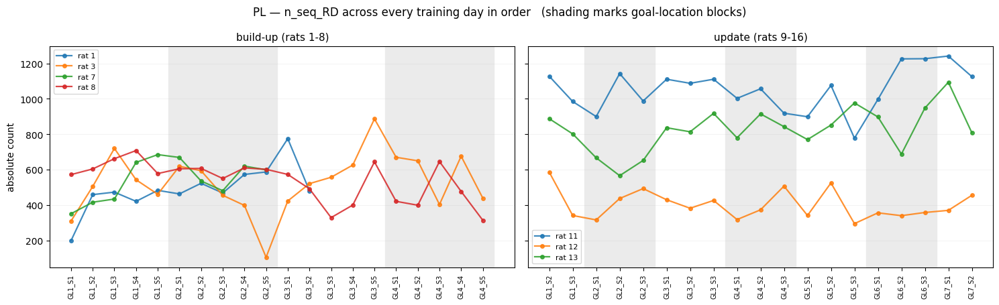

saved: 05_hc_n_seq_RD_PL


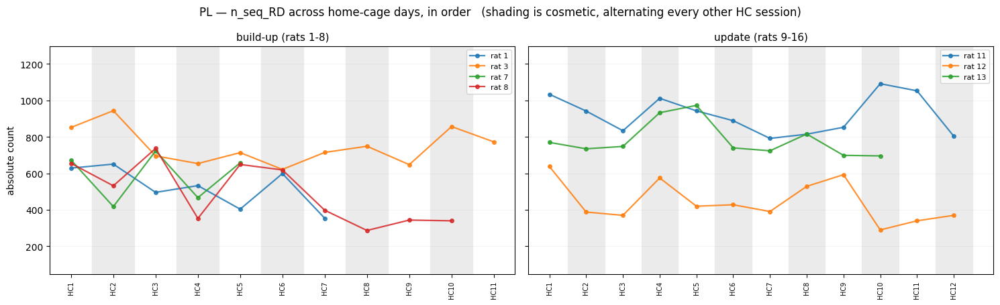

saved: 04_blocks_n_seq_RD_RSC


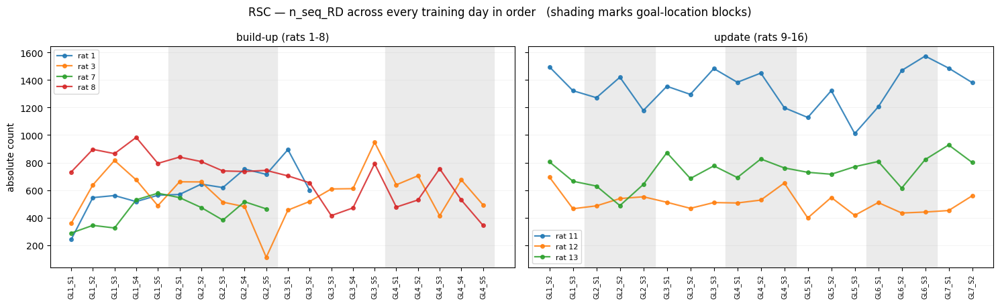

saved: 05_hc_n_seq_RD_RSC


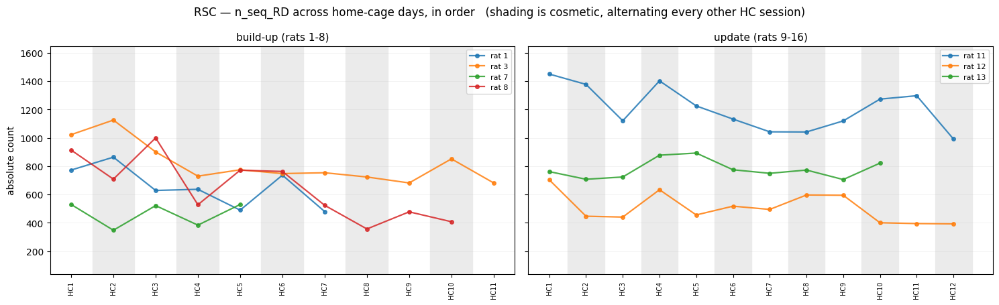

saved: 04_blocks_n_seq_RD_HPC


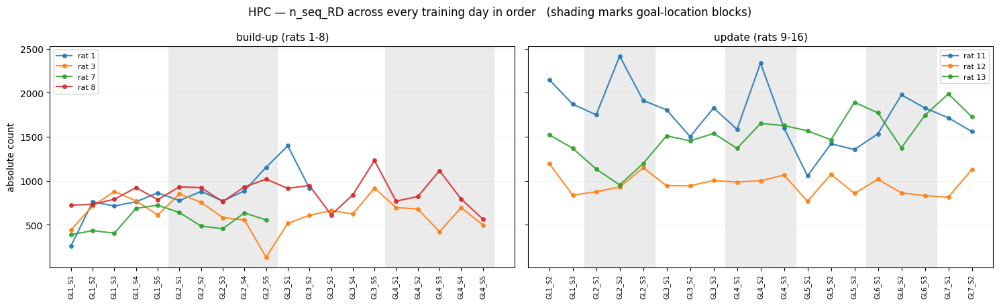

saved: 05_hc_n_seq_RD_HPC


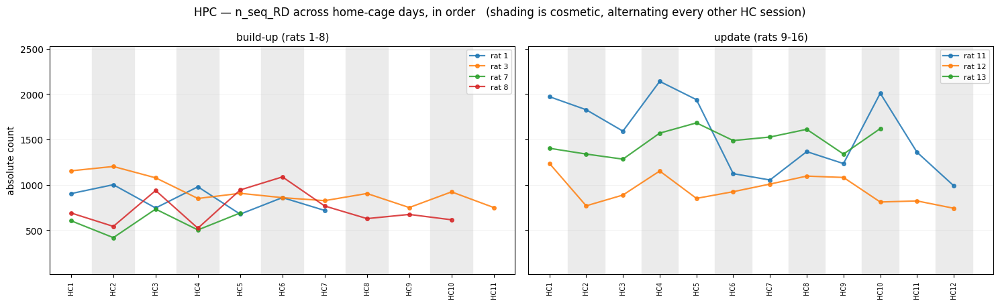

In [59]:
daily_nrem["n_seq_RD"] = daily_nrem["n_seq"]
for area in AREAS:
    ylim = get_shared_ylim("n_seq_RD", area)
    block_figure_count("n_seq_RD", area, ylim=ylim)
    hc_block_figure("n_seq_RD", area, ylim=ylim)

## D->R, absolute count

In [ ]:
for area in AREAS:
    ylim = get_shared_ylim("n_seq_DR", area)
    block_figure_count("n_seq_DR", area, ylim=ylim)
    hc_block_figure("n_seq_DR", area, ylim=ylim)

# Ripple-anchored proportion, normalized to the home-cage baseline

Based on Yixiao's feedback (Sept 2026) on the count plots:

1. Ripple-anchored proportion for R->D, D->R and ripple-in-spindle: ripples with a partner in the window / all ripples that day.

2. Normalized to HC two ways: nearest HC session in time (`_hcnorm`) and the rat's average over all HC days (`_avghcnorm`).

Columns are called `prop_ripple_*` to keep them apart from the chance-corrected `ratio_*`; the plots label the y-axis "ratio".

Both normalizations are tested on synthetic data first.

In [60]:
def count_ripples_with_partner(rip, dlt, lag_lo, lag_hi):
    """Unique ripples with a delta wave in the given lag window, per rat-day.

    lag = ripple_peak - delta_peak (project convention: negative = ripple first)
      Ripple->Delta  (ripple leads):  window [-250, -50]
      Delta->Ripple, ripple-anchored (delta leads, but counted per ripple,
                     per Yixiao's "consistently use ripple as the reference
                     event" instruction): window [+50, +400]
    """
    rows = []
    for (rat, date), rg in rip.groupby(["rat", "date"]):
        dg = dlt[(dlt["rat"] == rat) & (dlt["date"] == date)]
        n_coupled = 0
        for bout in rg["nrem_bout_index"].unique():
            r_b = rg.loc[rg["nrem_bout_index"] == bout, "ripple_peak_index"].values
            d_b = (
                dg.loc[dg["nrem_bout_index"] == bout, "delta_peak_index"].values
                if not dg.empty
                else np.array([])
            )
            if len(r_b) == 0 or len(d_b) == 0:
                continue
            lags = r_b[:, None] - d_b[None, :]
            has_partner = ((lags >= lag_lo) & (lags < lag_hi)).any(axis=1)
            n_coupled += int(has_partner.sum())
        rows.append(
            {"rat": rat, "date": date, "n_coupled": n_coupled, "n_ripple": len(rg)}
        )
    return pd.DataFrame(rows)


def _synth_partner(n_days=3, seed=0):
    rng = np.random.default_rng(seed)
    D, R = [], []
    for day in range(1, n_days + 1):
        d = np.sort(rng.uniform(0, 20000, 60))
        r = np.sort(rng.uniform(0, 20000, 10))
        if day == 2:
            take = rng.choice(len(d), 4, replace=False)
            r = np.sort(np.concatenate([r, d[take] + 140]))  # ripple leads
        if day == 3:
            take = rng.choice(len(d), 4, replace=False)
            r = np.sort(np.concatenate([r, d[take] - 140]))  # delta leads
        r = r[(r > 0) & (r < 20000)]
        D.append(
            pd.DataFrame(
                {
                    "rat": 1,
                    "date": f"day{day}",
                    "nrem_bout_index": 0,
                    "delta_peak_index": d,
                }
            )
        )
        R.append(
            pd.DataFrame(
                {
                    "rat": 1,
                    "date": f"day{day}",
                    "nrem_bout_index": 0,
                    "ripple_peak_index": r,
                }
            )
        )
    return pd.concat(D, ignore_index=True), pd.concat(R, ignore_index=True)


_dlt, _rip = _synth_partner()

_rd = count_ripples_with_partner(_rip, _dlt, -250, -50)
assert _rd.loc[_rd.date == "day2", "n_coupled"].iloc[0] >= 4
assert (
    _rd.loc[_rd.date == "day2", "n_coupled"].iloc[0]
    > _rd.loc[_rd.date == "day1", "n_coupled"].iloc[0]
)
print("Ripple->Delta self-test PASSED")

_dr = count_ripples_with_partner(_rip, _dlt, 50, 400)
assert _dr.loc[_dr.date == "day3", "n_coupled"].iloc[0] >= 4
assert (
    _dr.loc[_dr.date == "day3", "n_coupled"].iloc[0]
    > _dr.loc[_dr.date == "day1", "n_coupled"].iloc[0]
)
print("Delta->Ripple (ripple-anchored) self-test PASSED")

Ripple->Delta self-test PASSED
Delta->Ripple (ripple-anchored) self-test PASSED


In [61]:
def nearest_hc_normalize(df, value_col):
    """For each training day, divide by the nearest home-cage day's value
    (same rat, same area). If the nearest HC day is 0, falls back to the
    second-nearest (capped at two attempts). If that is also 0, the
    training day is dropped and reported in `dropped`."""
    out_rows, dropped = [], []
    for (rat, area), g in df.groupby(["rat", "area"]):
        hc = g[g["group"] == "HC"].sort_values("days_elapsed")
        train = g[g["group"] == "Training"]
        if hc.empty or train.empty:
            continue
        for _, row in train.iterrows():
            hc_sorted = hc.iloc[
                (hc["days_elapsed"] - row["days_elapsed"]).abs().argsort()
            ]
            used = None
            for rank, (_, hc_row) in enumerate(hc_sorted.iterrows()):
                if rank >= 2:
                    break
                if hc_row[value_col] and hc_row[value_col] > 0:
                    used = hc_row
                    break
            if used is None:
                nearest_two = hc_sorted.head(2)
                dropped.append(
                    {
                        "rat": rat,
                        "area": area,
                        "date": row["date"],
                        "days_elapsed": row["days_elapsed"],
                        "nearest_hc_days_elapsed": list(nearest_two["days_elapsed"]),
                    }
                )
                continue
            out_rows.append(
                {
                    **row.to_dict(),
                    "ratio": row[value_col] / used[value_col],
                    "nearest_hc_days_elapsed": used["days_elapsed"],
                }
            )
    return pd.DataFrame(out_rows), dropped


_test_df = pd.DataFrame(
    [
        {"rat": 1, "area": "HPC", "group": "HC", "days_elapsed": 5, "prop": 0.0},
        {"rat": 1, "area": "HPC", "group": "HC", "days_elapsed": 10, "prop": 0.30},
        {"rat": 1, "area": "HPC", "group": "HC", "days_elapsed": 20, "prop": 0.40},
        {"rat": 1, "area": "HPC", "group": "Training", "days_elapsed": 6, "prop": 0.60},
    ]
)
_res, _drop = nearest_hc_normalize(_test_df, "prop")
assert _res["nearest_hc_days_elapsed"].iloc[0] == 10, (
    "fallback to second-nearest did not fire"
)
assert abs(_res["ratio"].iloc[0] - 0.60 / 0.30) < 1e-9
assert len(_drop) == 0
print("Nearest-HC-session (with fallback) self-test PASSED")


def avg_hc_normalize(df, value_col):
    """For each training day, divide by THAT RAT's own average value across
    ALL its HC days (same rat, same area)."""
    out_rows = []
    for (rat, area), g in df.groupby(["rat", "area"]):
        hc = g[g["group"] == "HC"]
        train = g[g["group"] == "Training"]
        if hc.empty or train.empty:
            continue
        hc_mean = hc[value_col].mean()
        if not hc_mean or hc_mean <= 0 or np.isnan(hc_mean):
            continue
        for _, row in train.iterrows():
            out_rows.append(
                {
                    **row.to_dict(),
                    "ratio": row[value_col] / hc_mean,
                    "hc_mean": hc_mean,
                    "n_hc_days": len(hc),
                }
            )
    return pd.DataFrame(out_rows)


_test_df2 = pd.DataFrame(
    [
        {"rat": 1, "area": "HPC", "group": "HC", "days_elapsed": 5, "prop": 0.20},
        {"rat": 1, "area": "HPC", "group": "HC", "days_elapsed": 10, "prop": 0.30},
        {"rat": 1, "area": "HPC", "group": "HC", "days_elapsed": 20, "prop": 0.40},
        {
            "rat": 1,
            "area": "HPC",
            "group": "Training",
            "days_elapsed": 12,
            "prop": 0.60,
        },
    ]
)
_res2 = avg_hc_normalize(_test_df2, "prop")
_expected_mean = np.mean([0.20, 0.30, 0.40])
assert abs(_res2["hc_mean"].iloc[0] - _expected_mean) < 1e-9
assert abs(_res2["ratio"].iloc[0] - 0.60 / _expected_mean) < 1e-9
print("Average-HC-normalization self-test PASSED")

Nearest-HC-session (with fallback) self-test PASSED
Average-HC-normalization self-test PASSED


## Ripple->Delta: ripple-anchored proportion

Fraction of ripples with a delta 50-250 ms later.

In [62]:
prop_rd_rows = []
for area in AREAS:
    d = dlt_ctx[dlt_ctx["area"] == area]
    for (rat, date), rg in rip_ctx.groupby(["rat", "date"]):
        dg = d[(d["rat"] == rat) & (d["date"] == date)]
        t = count_ripples_with_partner(
            rg.assign(date=date), dg.assign(date=date), -250, -50
        )
        if t.empty or t["n_ripple"].iloc[0] == 0:
            continue
        row = rip_ctx[(rip_ctx["rat"] == rat) & (rip_ctx["date"] == date)].iloc[0]
        prop_rd_rows.append(
            {
                "rat": rat,
                "date": date,
                "area": area,
                "prop_ripple_RD": t["n_coupled"].iloc[0] / t["n_ripple"].iloc[0],
                "group": row["group"],
                "days_elapsed": row["days_elapsed"],
                "gl_num": row.get("gl_num"),
                "session_num": row.get("session_num"),
            }
        )

prop_rd = pd.DataFrame(prop_rd_rows)
print(f"{len(prop_rd)} rat-day-area rows")
print(prop_rd.groupby(["area", "group"])["prop_ripple_RD"].median().to_string())

558 rat-day-area rows
area  group   
HPC   HC          0.473762
      Training    0.468103
PL    HC          0.323120
      Training    0.310212
RSC   HC          0.363494
      Training    0.346090


## Delta->Ripple: ripple-anchored proportion

Fraction of ripples with a delta 50-400 ms before.

In [64]:
prop_dr_rows = []
for area in AREAS:
    d = dlt_ctx[dlt_ctx["area"] == area]
    for (rat, date), rg in rip_ctx.groupby(["rat", "date"]):
        dg = d[(d["rat"] == rat) & (d["date"] == date)]
        t = count_ripples_with_partner(
            rg.assign(date=date), dg.assign(date=date), 50, 400
        )
        if t.empty or t["n_ripple"].iloc[0] == 0:
            continue
        row = rip_ctx[(rip_ctx["rat"] == rat) & (rip_ctx["date"] == date)].iloc[0]
        prop_dr_rows.append(
            {
                "rat": rat,
                "date": date,
                "area": area,
                "prop_ripple_DR": t["n_coupled"].iloc[0] / t["n_ripple"].iloc[0],
                "group": row["group"],
                "days_elapsed": row["days_elapsed"],
                "gl_num": row.get("gl_num"),
                "session_num": row.get("session_num"),
            }
        )

prop_dr = pd.DataFrame(prop_dr_rows)
print(f"{len(prop_dr)} rat-day-area rows")
print(prop_dr.groupby(["area", "group"])["prop_ripple_DR"].median().to_string())

558 rat-day-area rows
area  group   
HPC   HC          0.533333
      Training    0.537305
PL    HC          0.482143
      Training    0.470401
RSC   HC          0.494386
      Training    0.491289


## Ripple-in-Spindle: ripple-anchored proportion

Fraction of ripples inside a spindle.

In [65]:
spindles = add_condition(
    build_wave(ROOT, "spindle", SPINDLE_METHOD, PHASES, WAVE_CACHE, rebuild=False),
    SESSION_MAP_CSV,
)

spn = spindles[
    (spindles["rat"].isin(RATS))
    & (spindles["group"] != "other")
    & (spindles["area"].isin(AREAS))
]

print(f"{len(spn):,} spindles")
print(spn.groupby("area").size().to_string())

spindle: 48 units to gather
  excluded 12,114 rows from 16 bad recording days
  16,338 rows had no trial number (16 rat-days) -> filled with 1
163,477 spindles
area
HPC    83274
PL     31128
RSC    49075


In [66]:
def add_spindle_context(df):
    df = add_gl_sessions(prep_keys(df), gl)
    df = df.merge(
        prep_keys(days)[["rat", "date", "session_type"]].drop_duplicates(),
        on=["rat", "date"],
        how="left",
    )
    return df


spn_ctx = add_spindle_context(spn)
spn_ctx = spn_ctx.merge(
    rip_ctx[["rat", "date", "days_elapsed"]].drop_duplicates(),
    on=["rat", "date"],
    how="left",
)

print(
    spn_ctx.groupby(["rat", "group"])["date"]
    .nunique()
    .unstack(fill_value=0)
    .to_string()
)

group  HC  Training
rat                
1       7        12
3      11        20
7       5        10
8      10        20
11     12        19
12     12        19
13     10        19


In [67]:
from modules.event_coupling import spindle_ripple as sr

RULE = "any_overlap"  # slide 7 / Navarro Lobato: partial overlaps count

prop_sp_rows = []
for area in AREAS:
    s = spn_ctx[spn_ctx["area"] == area]
    for (rat, date), rg in rip_ctx.groupby(["rat", "date"]):
        sg_ = s[(s["rat"] == rat) & (s["date"] == date)]
        if sg_.empty or len(rg) == 0:
            continue
        t = sr.count_overlap(sg_, rg, rule=RULE)
        n_rip = t["n_ripple"].sum()
        if n_rip == 0:
            continue
        row = rip_ctx[(rip_ctx["rat"] == rat) & (rip_ctx["date"] == date)].iloc[0]
        prop_sp_rows.append(
            {
                "rat": rat,
                "date": date,
                "area": area,
                "prop_ripple_spindle": t["n_coupled"].sum() / n_rip,
                "group": row["group"],
                "days_elapsed": row["days_elapsed"],
                "gl_num": row.get("gl_num"),
                "session_num": row.get("session_num"),
            }
        )

prop_sp = pd.DataFrame(prop_sp_rows)
print(f"{len(prop_sp)} rat-day-area rows")
print(prop_sp.groupby(["area", "group"])["prop_ripple_spindle"].median().to_string())

558 rat-day-area rows
area  group   
HPC   HC          0.103578
      Training    0.133333
PL    HC          0.022959
      Training    0.023256
RSC   HC          0.050324
      Training    0.054911


## Normalize each measure to a home-cage baseline, both ways

In [68]:
# NREM cutoff, as for the trend statistics
prop_rd = prop_rd.merge(good_days, on=["rat", "date"])
prop_dr = prop_dr.merge(good_days, on=["rat", "date"])
prop_sp = prop_sp.merge(good_days, on=["rat", "date"])

prop_rd_hcnorm, dropped_rd = nearest_hc_normalize(prop_rd, "prop_ripple_RD")
prop_dr_hcnorm, dropped_dr = nearest_hc_normalize(prop_dr, "prop_ripple_DR")
prop_sp_hcnorm, dropped_sp = nearest_hc_normalize(prop_sp, "prop_ripple_spindle")

prop_rd_avghcnorm = avg_hc_normalize(prop_rd, "prop_ripple_RD")
prop_dr_avghcnorm = avg_hc_normalize(prop_dr, "prop_ripple_DR")
prop_sp_avghcnorm = avg_hc_normalize(prop_sp, "prop_ripple_spindle")

for name, hcn, avgn, dropped in [
    ("Ripple->Delta", prop_rd_hcnorm, prop_rd_avghcnorm, dropped_rd),
    ("Delta->Ripple", prop_dr_hcnorm, prop_dr_avghcnorm, dropped_dr),
    ("Ripple-in-Spindle", prop_sp_hcnorm, prop_sp_avghcnorm, dropped_sp),
]:
    print(
        f"{name}: {len(hcn)} days normalized to nearest HC session "
        f"({len(dropped)} dropped -- both nearest tries were 0) | "
        f"{len(avgn)} days normalized to that rat's own average HC"
    )

all_dropped = dropped_rd + dropped_dr + dropped_sp
if all_dropped:
    print("=== rat-days dropped from _hcnorm (both nearest-HC tries were 0) ===")
    for d in all_dropped:
        print(
            f"  rat {d['rat']} {d['area']}, {d['date']} (days_elapsed={d['days_elapsed']}): "
            f"nearest two HC days {d['nearest_hc_days_elapsed']} both had 0"
        )

Ripple->Delta: 357 days normalized to nearest HC session (0 dropped -- both nearest tries were 0) | 357 days normalized to that rat's own average HC
Delta->Ripple: 357 days normalized to nearest HC session (0 dropped -- both nearest tries were 0) | 357 days normalized to that rat's own average HC
Ripple-in-Spindle: 357 days normalized to nearest HC session (0 dropped -- both nearest tries were 0) | 357 days normalized to that rat's own average HC


## Plots

Per coupling type and area: training and HC days (raw), then both HC normalizations.

In [ ]:
def block_figure_normalized(df, area, label, suffix, title_phrase):
    """GL-shaded, per-cohort layout, plotting an HC-normalized ratio with a
    chance line at 1.0. `suffix` and `title_phrase` distinguish the two
    normalizations (_hcnorm / _avghcnorm) in the saved filename and title."""
    sub_all = df[df["area"] == area].dropna(subset=["gl_num", "session_num"])
    if sub_all.empty:
        return

    fig, axes = plt.subplots(1, 2, figsize=(15, 4.6), sharey=True)
    for ax, (cohort_label, rats) in zip(axes, COHORTS.items()):
        sub = sub_all[sub_all["rat"].isin(rats)].copy()
        if sub.empty:
            ax.set_title(cohort_label, fontsize=11)
            continue
        sub["step"] = sub["gl_num"] * 10 + sub["session_num"]
        order = sorted(sub["step"].unique())
        pos = {s: i for i, s in enumerate(order)}
        tick_labels = [f"GL{int(s // 10)}_S{int(s % 10)}" for s in order]

        # Collect each rat's GL × Session curve
        rat_curves = {}

        for rat in rats:

            r = sub[sub["rat"] == rat]

            if len(r) < 3:
                continue

            g = (
                r.groupby("step")["ratio"]
                .mean()
                .reindex(order)
            )

            rat_curves[rat] = g

        # Cohort-specific mean color
        cohort_color = (
            "tab:blue"
            if "build" in cohort_label.lower()
            else "tab:orange"
        )

        plot_rats_mean_sem(
            ax,
            rat_curves,
            order,
            color=cohort_color
        )

        for i, s in enumerate(order):
            if int(s // 10) % 2 == 0:
                ax.axvspan(i - 0.5, i + 0.5, color="0.92", zorder=0)
        ax.axhline(1, color="k", lw=1.2, ls=":")
        ax.set_xticks(range(len(tick_labels)))
        ax.set_xticklabels(tick_labels, rotation=90, fontsize=7)
        ax.set_title(cohort_label, fontsize=11)
        ax.legend(fontsize=8)
        ax.grid(alpha=0.2, lw=0.5, axis="y")

    axes[0].set_ylabel("ratio")
    fig.suptitle(
        f"{area} \u2014 normalized to {title_phrase}   "
        "(shading marks goal-location blocks)",
        fontsize=12,
    )
    plt.tight_layout()
    add_nrem_footnote(fig)
    save_fig(fig, f"ratio_{suffix}_{label}_{area}")
    plt.show()


def get_shared_ylim_prop(df, measure, area):
    train_vals = df[(df["area"] == area) & (df["group"] == "Training")][measure]
    hc_vals = df[(df["area"] == area) & (df["group"] == "HC")][measure]
    all_vals = pd.concat([train_vals, hc_vals]).dropna()
    if all_vals.empty:
        return None
    pad = 0.05 * (all_vals.max() - all_vals.min())
    return (all_vals.min() - pad, all_vals.max() + pad)


for measure_col, daily_df, hcn_df, avgn_df, label in [
    ("prop_ripple_RD", prop_rd, prop_rd_hcnorm, prop_rd_avghcnorm, "RippleToDelta"),
    ("prop_ripple_DR", prop_dr, prop_dr_hcnorm, prop_dr_avghcnorm, "DeltaToRipple"),
    (
        "prop_ripple_spindle",
        prop_sp,
        prop_sp_hcnorm,
        prop_sp_avghcnorm,
        "RippleInSpindle",
    ),
]:
    print(f"=== {label} ===")
    for area in AREAS:
        ylim = get_shared_ylim_prop(daily_df, measure_col, area)
        block_figure_normalized(
            hcn_df, area, label, "normalized_hcnorm", "nearest home-cage session"
        )
        block_figure_normalized(
            avgn_df,
            area,
            label,
            "normalized_avghcnorm",
            "that rat's own average HC (new)",
        )

In [77]:
def block_figure_averaged(
    df, area, label, suffix, title_phrase, average_over
):
    """
    Plot HC-normalized ratios averaged within each rat.

    average_over="session":
        Average sessions within each GL.
        X-axis = GL1, GL2, GL3, ...

    average_over="gl":
        Average GLs within each session.
        X-axis = S1, S2, S3, ...

    Plot:
        Individual rats = thin grey lines
        Cohort mean = thick colored line
        SEM = shaded area
    """

    sub_all = df[
        df["area"] == area
    ].dropna(
        subset=["gl_num", "session_num", "ratio"]
    ).copy()

    if sub_all.empty:
        return

    # -----------------------------------
    # Choose averaging method
    # -----------------------------------
    if average_over == "session":
        x_col = "gl_num"
        x_prefix = "GL"
        plot_title = "Average across sessions within each GL"
        save_suffix = "avg_sessions_per_GL"

    elif average_over == "gl":
        x_col = "session_num"
        x_prefix = "S"
        plot_title = "Average across GLs within each session"
        save_suffix = "avg_GLs_per_session"

    else:
        raise ValueError(
            "average_over must be 'session' or 'gl'"
        )

    # -----------------------------------
    # Average within each rat
    # -----------------------------------

    # First: rat × GL × session
    per_step = (
        sub_all
        .groupby(
            ["rat", "gl_num", "session_num"],
            as_index=False
        )["ratio"]
        .mean()
    )

    # Second: average sessions or GLs
    averaged = (
        per_step
        .groupby(
            ["rat", x_col],
            as_index=False
        )["ratio"]
        .mean()
    )

    # -----------------------------------
    # Figure
    # -----------------------------------
    fig, axes = plt.subplots(
        1, 2,
        figsize=(12, 4.6),
        sharey=True
    )

    for ax, (cohort_label, rats) in zip(
        axes, COHORTS.items()
    ):

        sub = averaged[
            averaged["rat"].isin(rats)
        ].copy()

        if sub.empty:
            ax.set_title(cohort_label, fontsize=11)
            continue

        order = sorted(sub[x_col].unique())
        x = np.arange(len(order))

        # Cohort color
        cohort_color = (
            "tab:blue"
            if "build" in cohort_label.lower()
            else "tab:orange"
        )

        # -----------------------------------
        # Individual rats
        # -----------------------------------
        rat_curves = {}

        # Individual rats — consistent colors
        rat_curves = {}

        RAT_COLORS = {
            1: "tab:blue",
            3: "tab:orange",
            7: "tab:green",
            8: "tab:red",
            11: "tab:purple",
            12: "tab:brown",
            13: "tab:pink",
        }

        for rat in rats:

            r = sub[sub["rat"] == rat]

            if r.empty:
                continue

            g = r.set_index(x_col)["ratio"].reindex(order)
            rat_curves[rat] = g

            ax.plot(
                x,
                g.values,
                color=RAT_COLORS.get(rat, "gray"),
                lw=1.5,
                alpha=0.85,
                marker="o",
                ms=4,
                label=f"rat {rat}",
                zorder=2
            )

        # -----------------------------------
        # Cohort mean ± SEM
        # -----------------------------------
        if rat_curves:

            rat_df = pd.DataFrame(
                rat_curves
            ).reindex(order)

            # Mean across rats
            mean = rat_df.mean(axis=1).to_numpy()

            # Number of rats per x position
            n = rat_df.notna().sum(axis=1).to_numpy()

            # SEM across rats
            sem = rat_df.sem(
                axis=1,
                ddof=1
            ).to_numpy()

            # SEM — light gray shading
            ax.fill_between(
                x,
                mean - sem,
                mean + sem,
                where=(n >= 2),
                color="0.5",
                alpha=0.18,
                linewidth=0,
                label="Mean ± SEM",
                zorder=3
            )

            # Cohort mean — thick black line
            ax.plot(
                x,
                mean,
                color="black",
                lw=3.5,
                marker="o",
                ms=7,
                markeredgecolor="white",
                markeredgewidth=0.8,
                label="Cohort mean",
                zorder=5
            )

        # -----------------------------------
        # GL background shading
        # -----------------------------------
        if average_over == "session":

            for i, gl in enumerate(order):

                if int(gl) % 2 == 0:

                    ax.axvspan(
                        i - 0.5,
                        i + 0.5,
                        color="0.92",
                        zorder=0
                    )

        # -----------------------------------
        # HC baseline
        # -----------------------------------
        ax.axhline(
            1,
            color="k",
            lw=1.2,
            ls=":",
            label="HC baseline"
        )

        # -----------------------------------
        # Axis formatting
        # -----------------------------------
        ax.set_xticks(x)

        ax.set_xticklabels(
            [f"{x_prefix}{int(v)}" for v in order],
            fontsize=9
        )

        ax.set_xlabel(
            "Goal Location"
            if average_over == "session"
            else "Session"
        )

        ax.set_title(
            cohort_label,
            fontsize=11
        )

        ax.legend(fontsize=8)

        ax.grid(
            alpha=0.2,
            lw=0.5,
            axis="y"
        )

    axes[0].set_ylabel(
        "HC-normalized ratio"
    )

    fig.suptitle(
        f"{area} — {plot_title}\n"
        f"Normalized to {title_phrase}",
        fontsize=12
    )

    plt.tight_layout()

    add_nrem_footnote(fig)

    save_fig(
        fig,
        f"ratio_{suffix}_{label}_{area}_{save_suffix}"
    )

    plt.show()

def plot_rats_mean_sem(ax, rat_curves, order, color):
    """
    Plot individual rat curves + cohort mean ± SEM.

    rat_curves:
        dictionary {rat: pd.Series}
        Each series is indexed by GL/session position.

    Each rat contributes equally to the mean.
    SEM is computed across rats, not events.
    """

    if not rat_curves:
        return

    x = np.arange(len(order))

    # Individual rats — thin grey lines
    for rat, curve in rat_curves.items():

        values = curve.reindex(order).to_numpy(dtype=float)

        ax.plot(
            x,
            values,
            color="0.7",
            lw=1.0,
            alpha=0.65,
            marker="o",
            ms=3,
            label=f"rat {rat}",
            zorder=2,
        )

    # Combine rats into one dataframe
    rat_df = pd.DataFrame(rat_curves).reindex(order)

    # Mean and SEM across rats at each x position
    mean = rat_df.mean(axis=1).to_numpy()
    sem = rat_df.sem(axis=1, ddof=1).to_numpy()
    n = rat_df.notna().sum(axis=1).to_numpy()

    # SEM shading, only where >= 2 rats contribute
    ax.fill_between(
        x,
        mean - sem,
        mean + sem,
        where=(n >= 2),
        color=color,
        alpha=0.20,
        linewidth=0,
        label="Mean ± SEM",
        zorder=3,
    )

    # Cohort mean — thick colored line
    ax.plot(
        x,
        mean,
        color=color,
        lw=3.0,
        marker="o",
        ms=6,
        markeredgecolor="white",
        markeredgewidth=0.8,
        label="Cohort mean",
        zorder=5,
    )


=== RippleToDelta ===
saved: ratio_normalized_hcnorm_RippleToDelta_PL_avg_sessions_per_GL


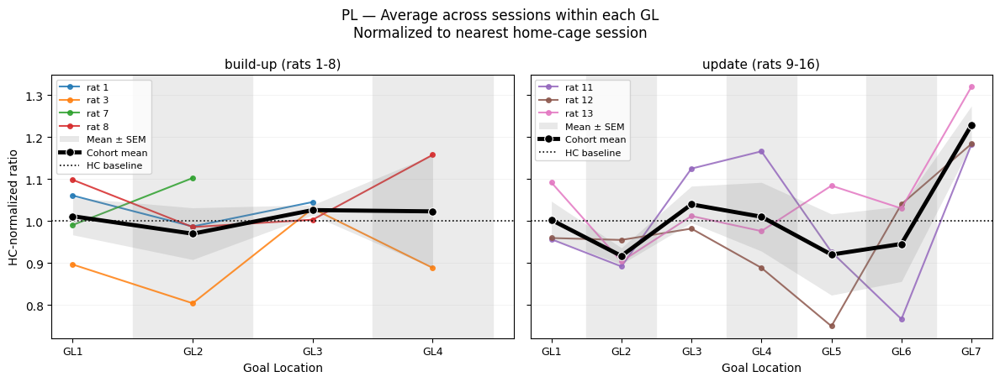

saved: ratio_normalized_hcnorm_RippleToDelta_PL_avg_GLs_per_session


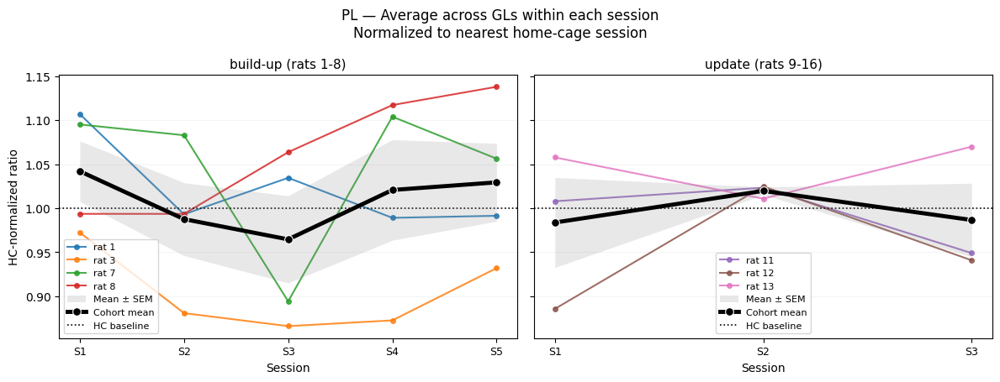

saved: ratio_normalized_avghcnorm_RippleToDelta_PL_avg_sessions_per_GL


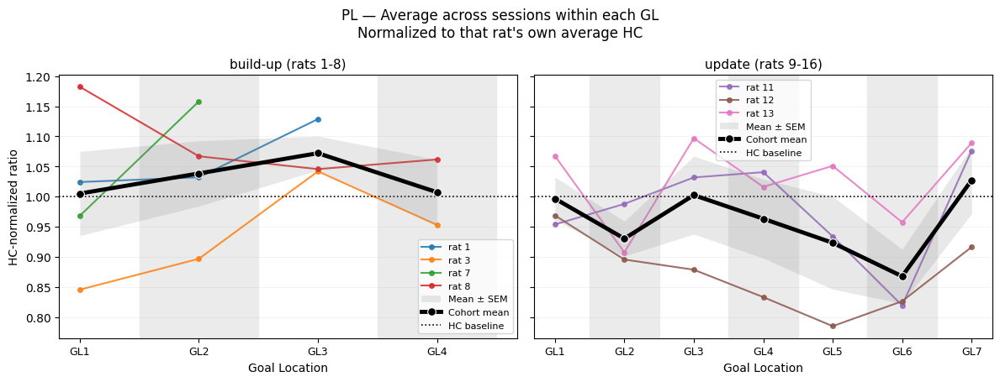

saved: ratio_normalized_avghcnorm_RippleToDelta_PL_avg_GLs_per_session


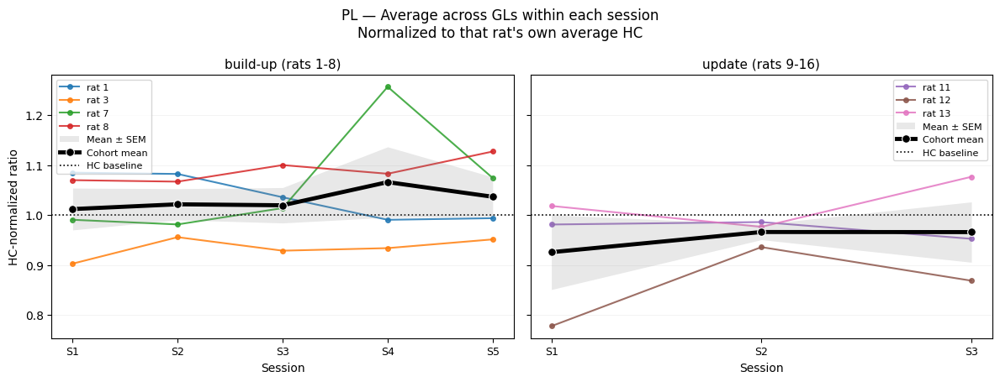

saved: ratio_normalized_hcnorm_RippleToDelta_RSC_avg_sessions_per_GL


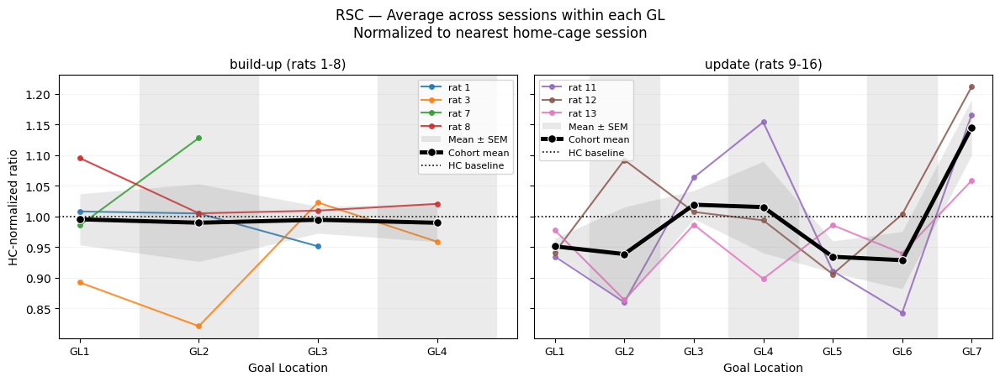

saved: ratio_normalized_hcnorm_RippleToDelta_RSC_avg_GLs_per_session


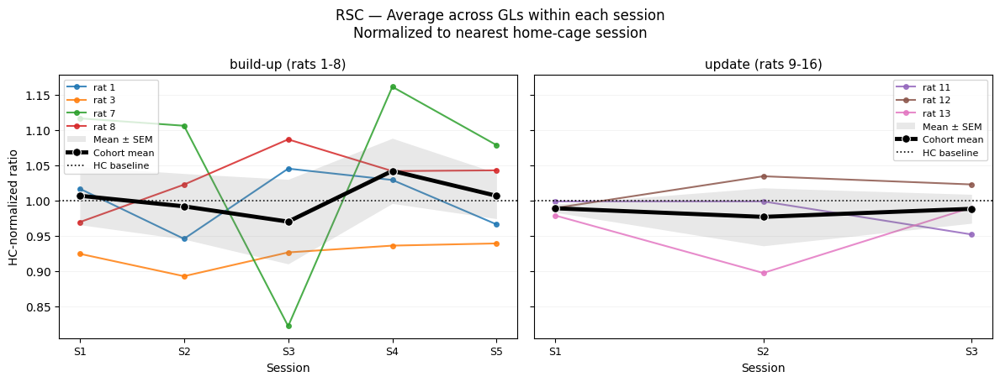

saved: ratio_normalized_avghcnorm_RippleToDelta_RSC_avg_sessions_per_GL


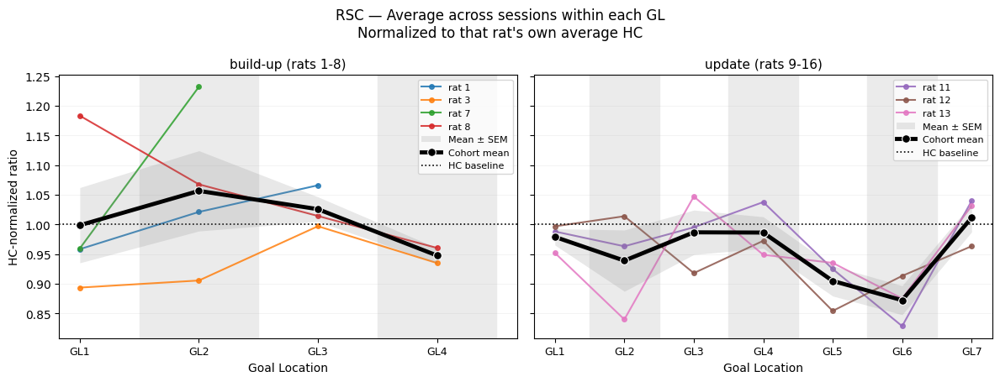

saved: ratio_normalized_avghcnorm_RippleToDelta_RSC_avg_GLs_per_session


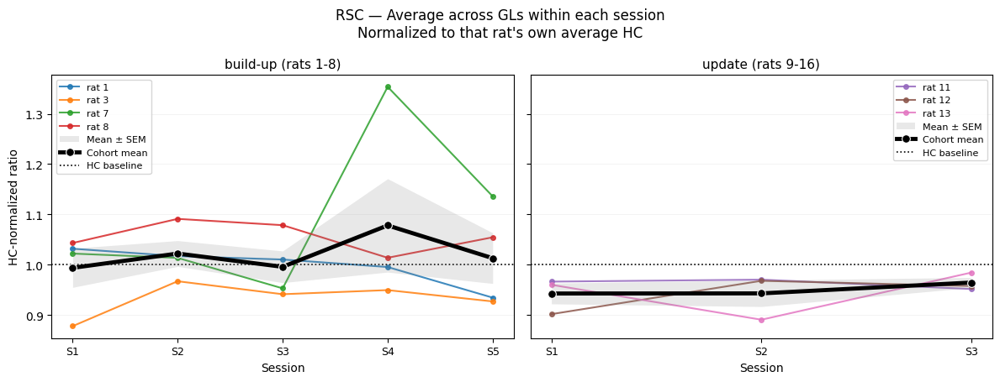

saved: ratio_normalized_hcnorm_RippleToDelta_HPC_avg_sessions_per_GL


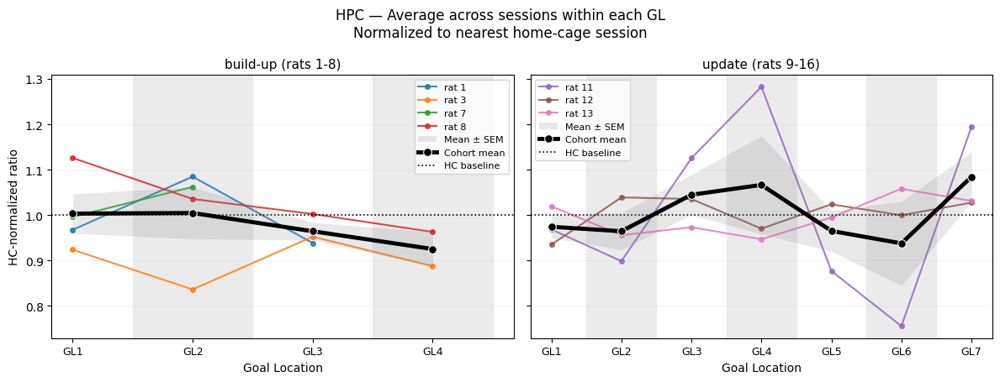

saved: ratio_normalized_hcnorm_RippleToDelta_HPC_avg_GLs_per_session


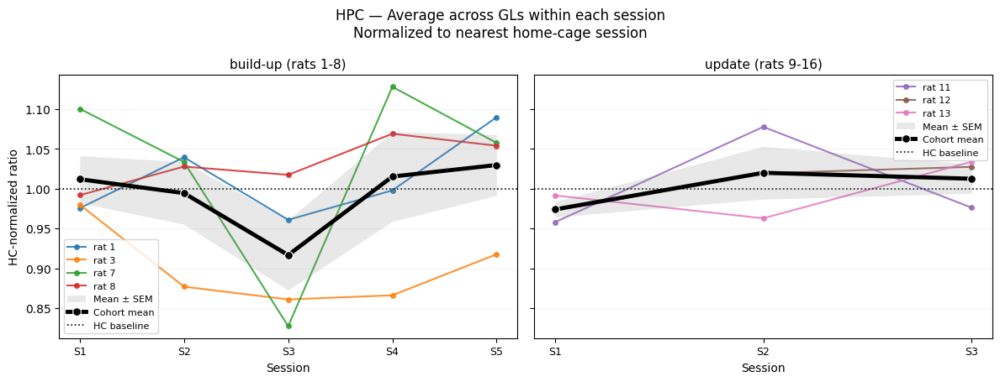

saved: ratio_normalized_avghcnorm_RippleToDelta_HPC_avg_sessions_per_GL


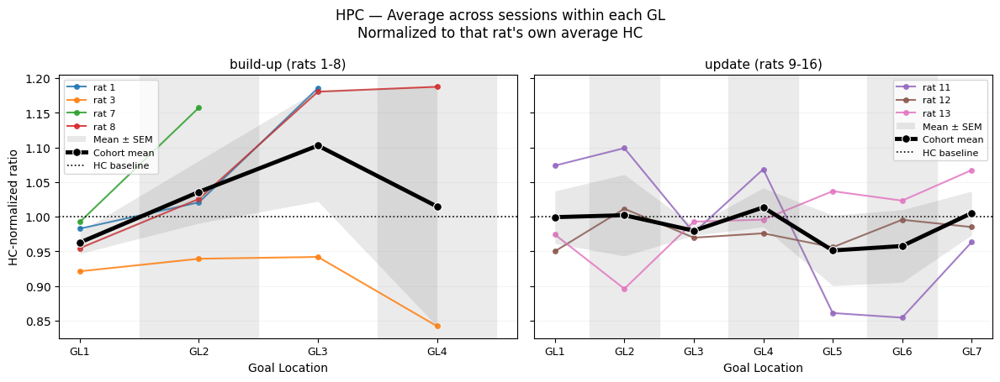

saved: ratio_normalized_avghcnorm_RippleToDelta_HPC_avg_GLs_per_session


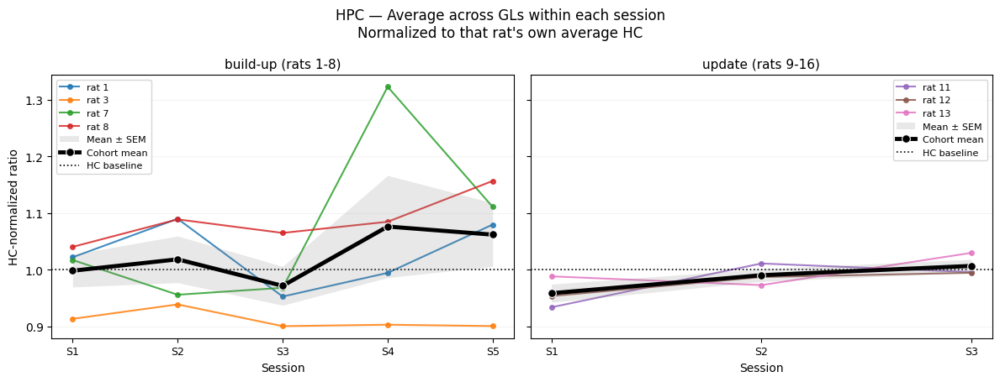

=== DeltaToRipple ===
saved: ratio_normalized_hcnorm_DeltaToRipple_PL_avg_sessions_per_GL


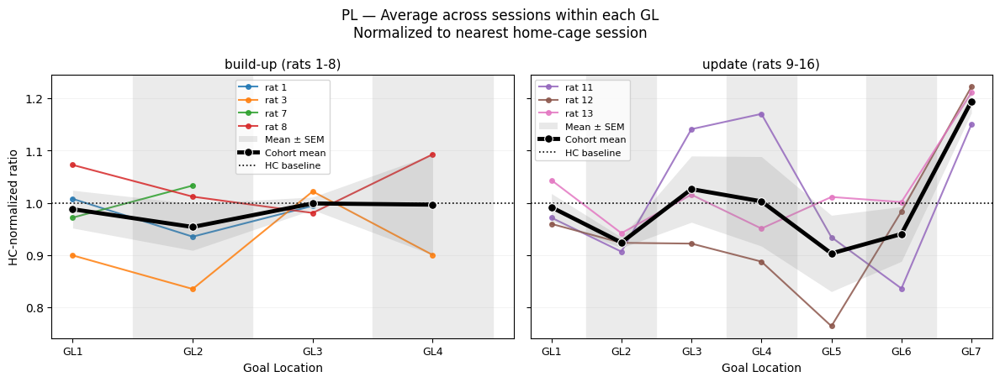

saved: ratio_normalized_hcnorm_DeltaToRipple_PL_avg_GLs_per_session


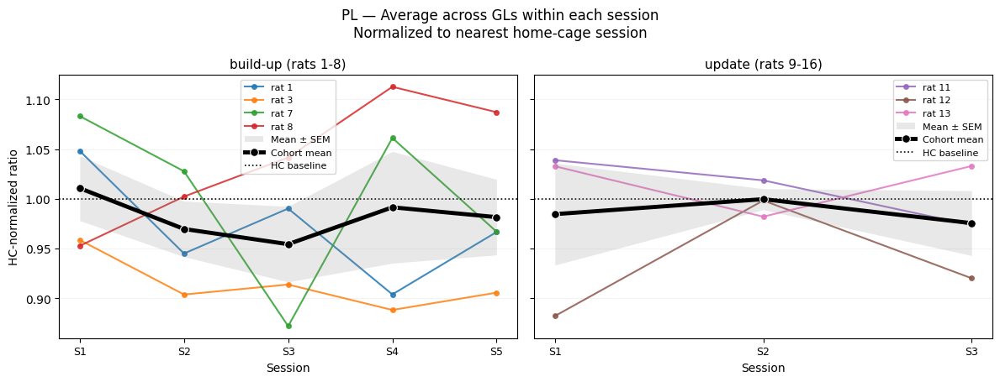

saved: ratio_normalized_avghcnorm_DeltaToRipple_PL_avg_sessions_per_GL


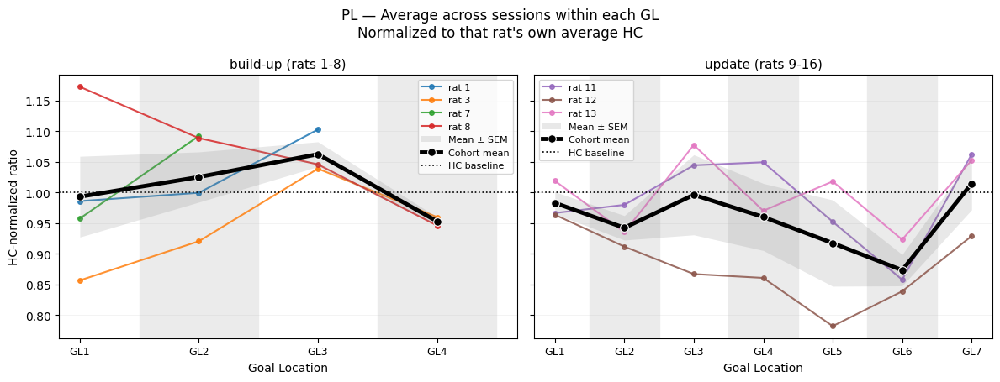

saved: ratio_normalized_avghcnorm_DeltaToRipple_PL_avg_GLs_per_session


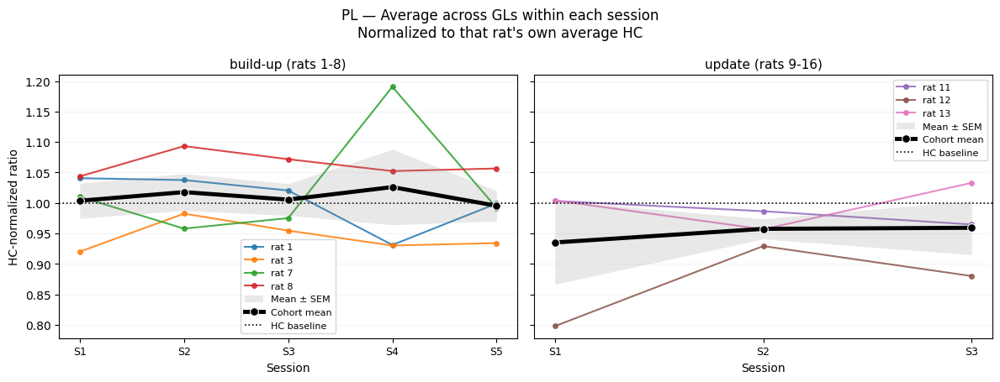

saved: ratio_normalized_hcnorm_DeltaToRipple_RSC_avg_sessions_per_GL


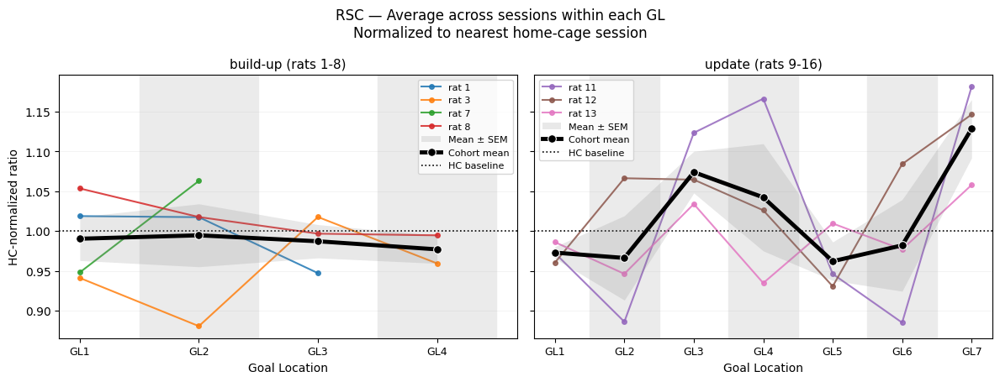

saved: ratio_normalized_hcnorm_DeltaToRipple_RSC_avg_GLs_per_session


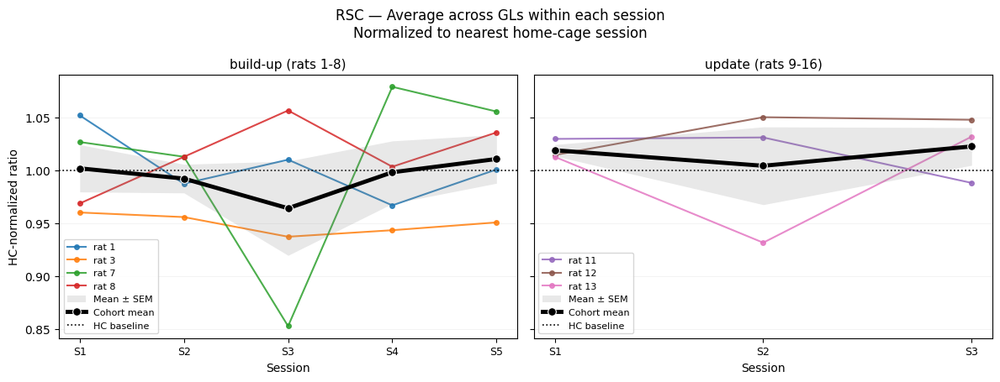

saved: ratio_normalized_avghcnorm_DeltaToRipple_RSC_avg_sessions_per_GL


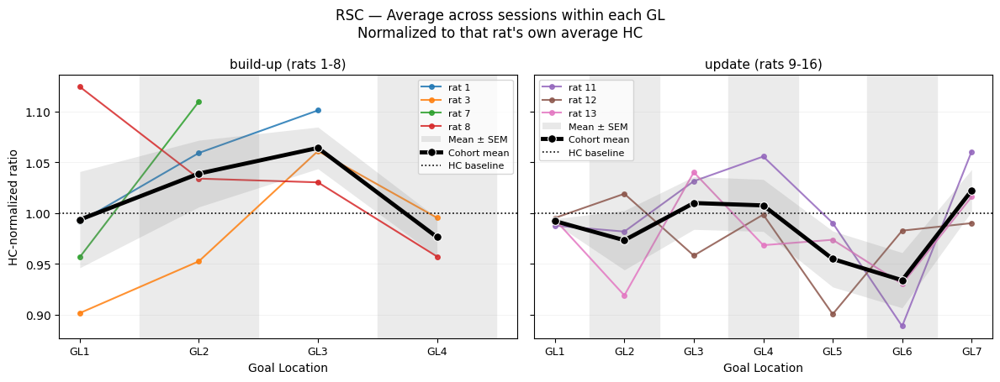

saved: ratio_normalized_avghcnorm_DeltaToRipple_RSC_avg_GLs_per_session


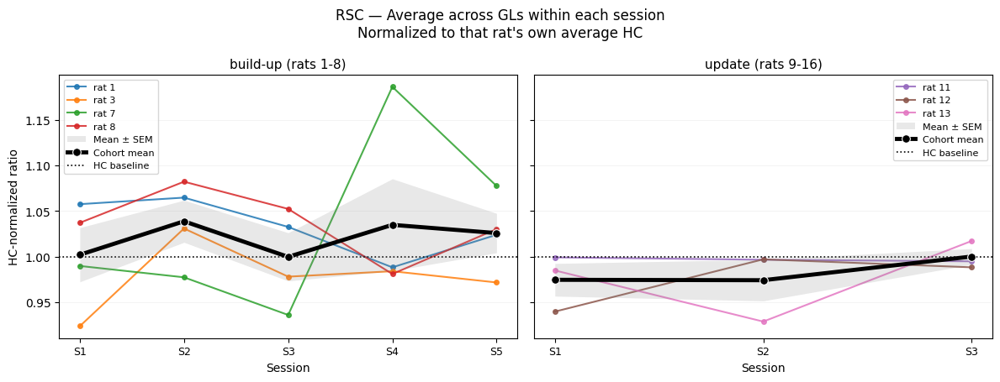

saved: ratio_normalized_hcnorm_DeltaToRipple_HPC_avg_sessions_per_GL


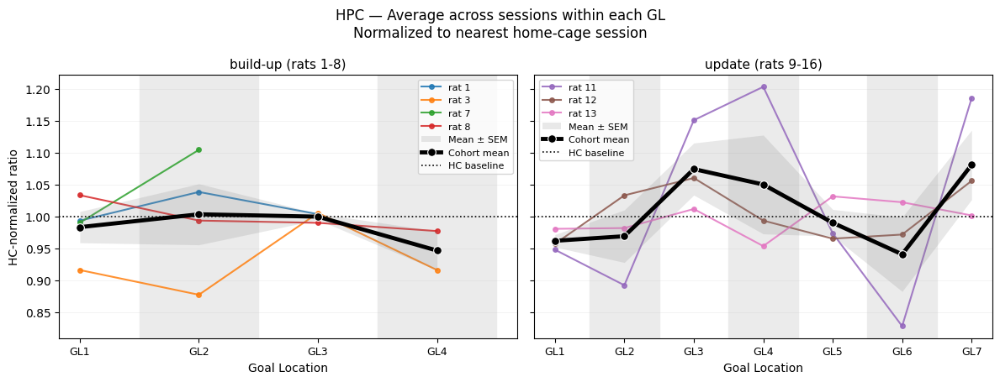

saved: ratio_normalized_hcnorm_DeltaToRipple_HPC_avg_GLs_per_session


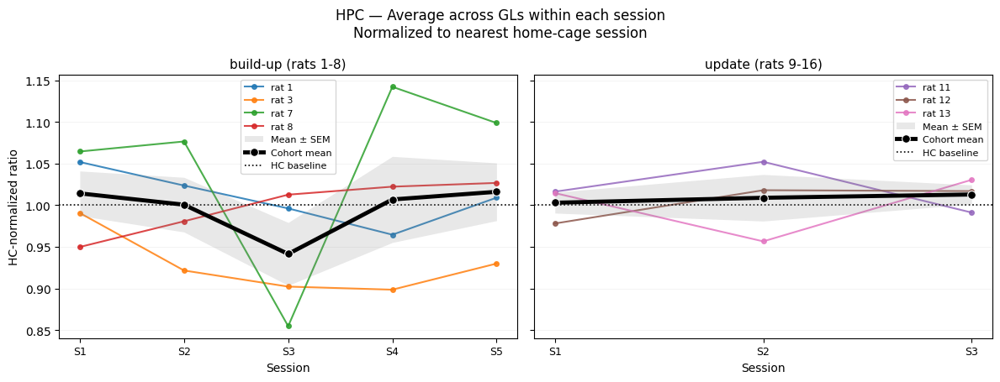

saved: ratio_normalized_avghcnorm_DeltaToRipple_HPC_avg_sessions_per_GL


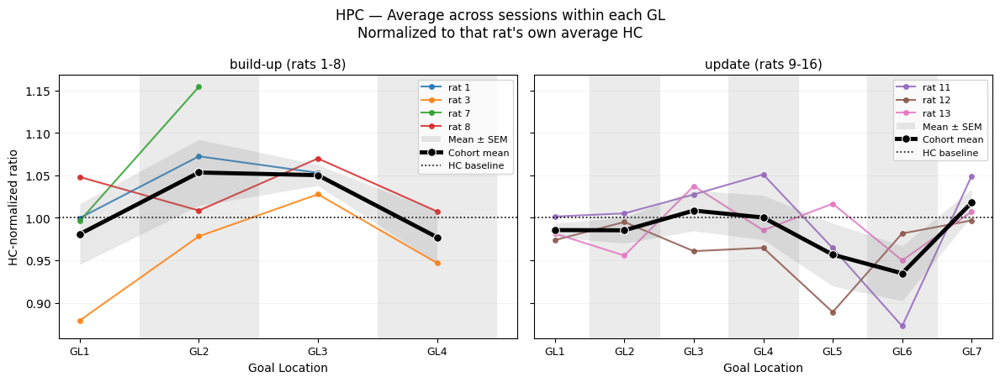

saved: ratio_normalized_avghcnorm_DeltaToRipple_HPC_avg_GLs_per_session


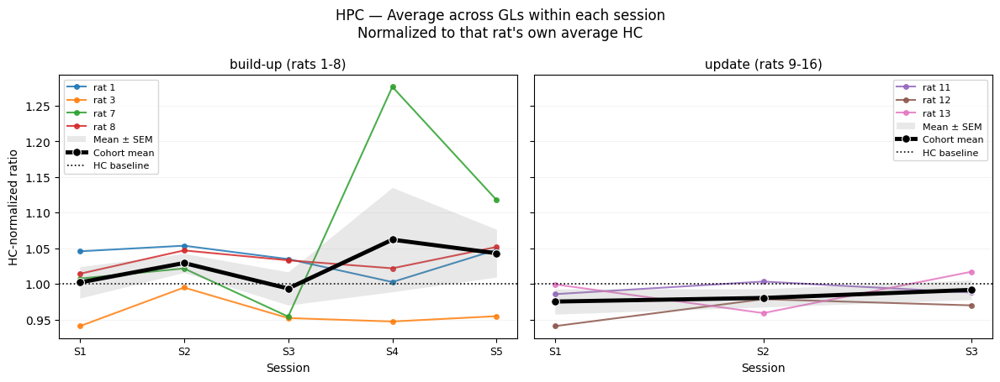

=== RippleInSpindle ===
saved: ratio_normalized_hcnorm_RippleInSpindle_PL_avg_sessions_per_GL


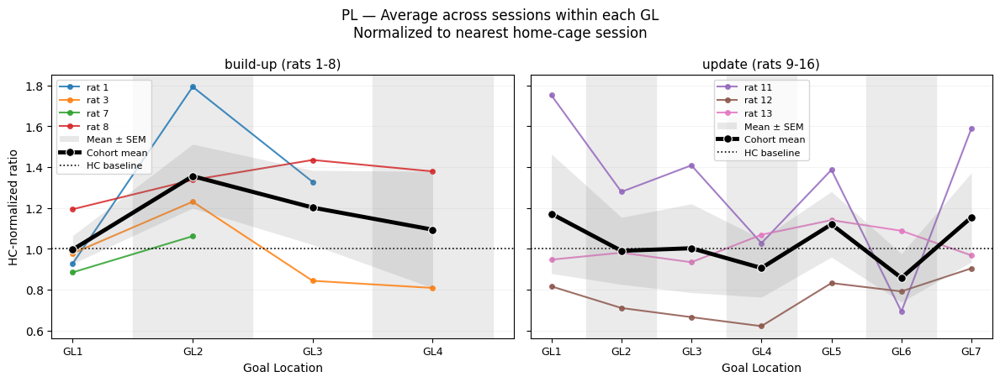

saved: ratio_normalized_hcnorm_RippleInSpindle_PL_avg_GLs_per_session


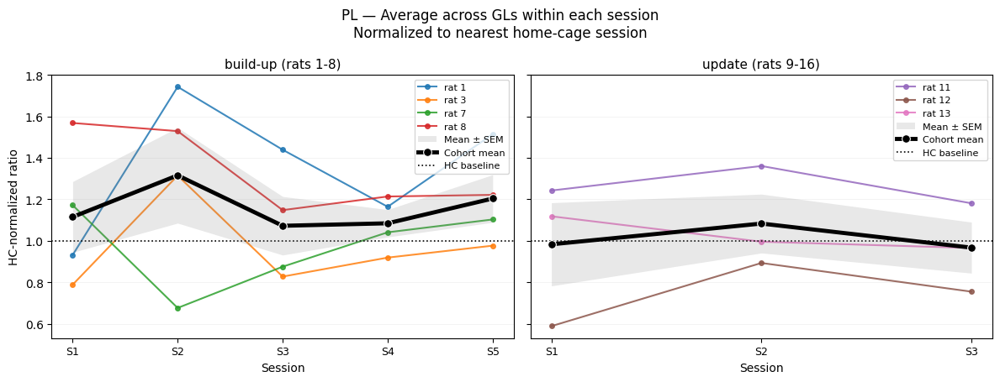

saved: ratio_normalized_avghcnorm_RippleInSpindle_PL_avg_sessions_per_GL


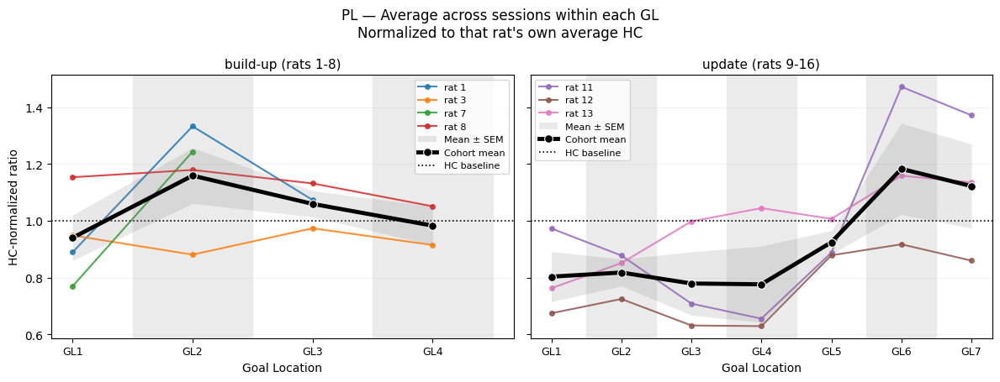

saved: ratio_normalized_avghcnorm_RippleInSpindle_PL_avg_GLs_per_session


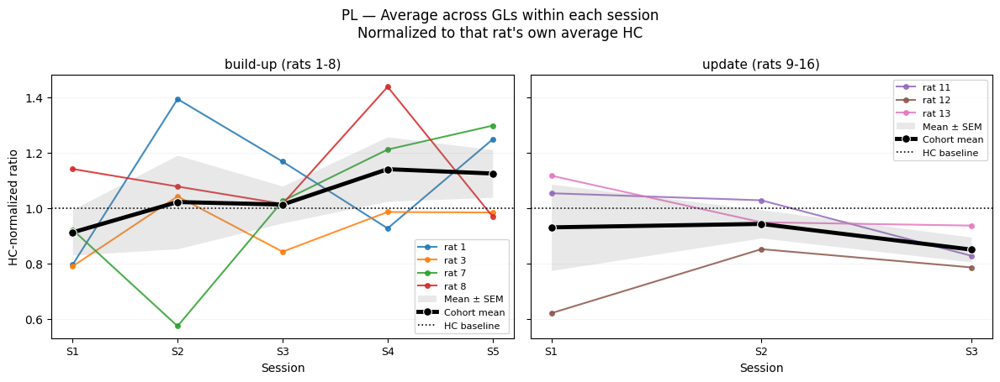

saved: ratio_normalized_hcnorm_RippleInSpindle_RSC_avg_sessions_per_GL


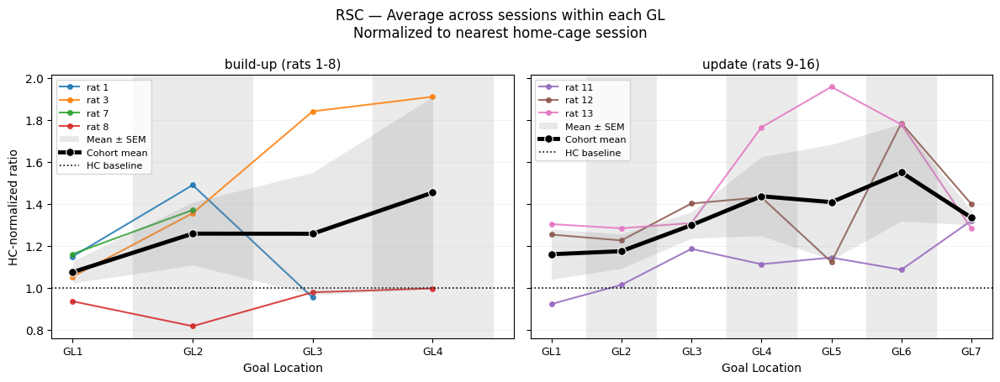

saved: ratio_normalized_hcnorm_RippleInSpindle_RSC_avg_GLs_per_session


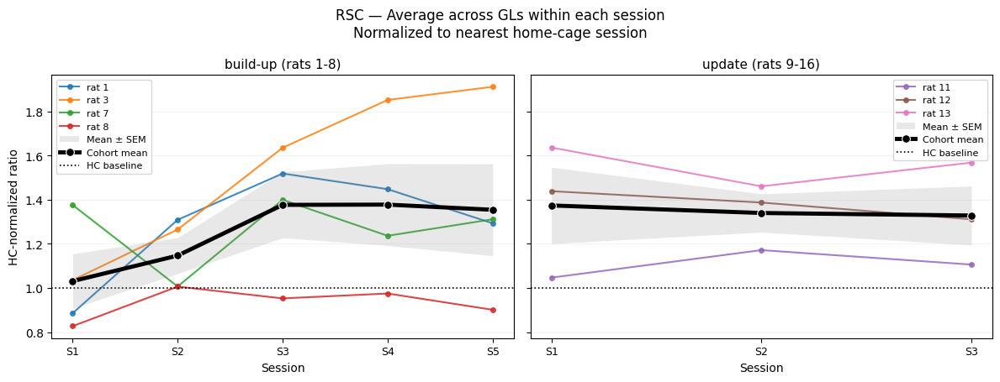

saved: ratio_normalized_avghcnorm_RippleInSpindle_RSC_avg_sessions_per_GL


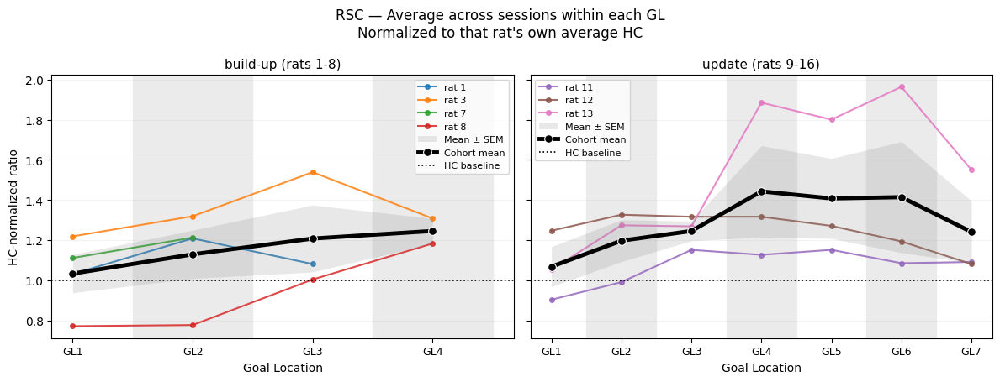

saved: ratio_normalized_avghcnorm_RippleInSpindle_RSC_avg_GLs_per_session


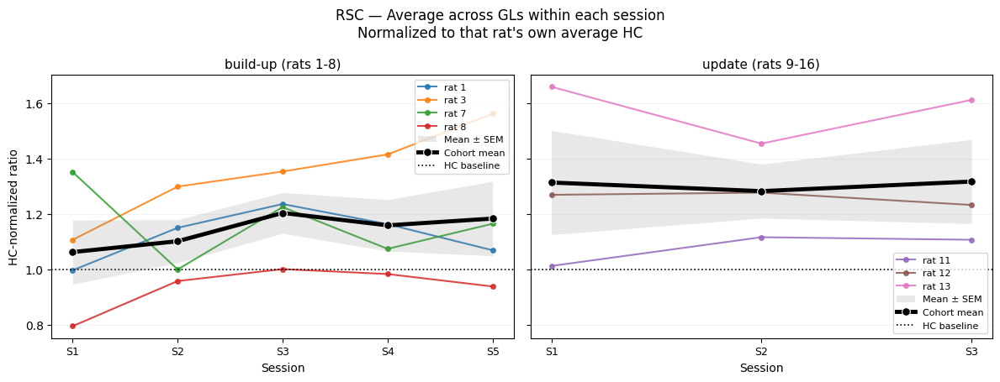

saved: ratio_normalized_hcnorm_RippleInSpindle_HPC_avg_sessions_per_GL


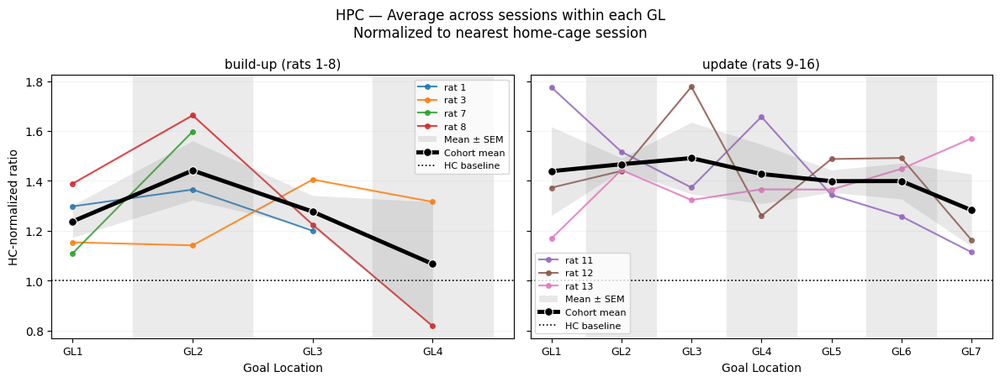

saved: ratio_normalized_hcnorm_RippleInSpindle_HPC_avg_GLs_per_session


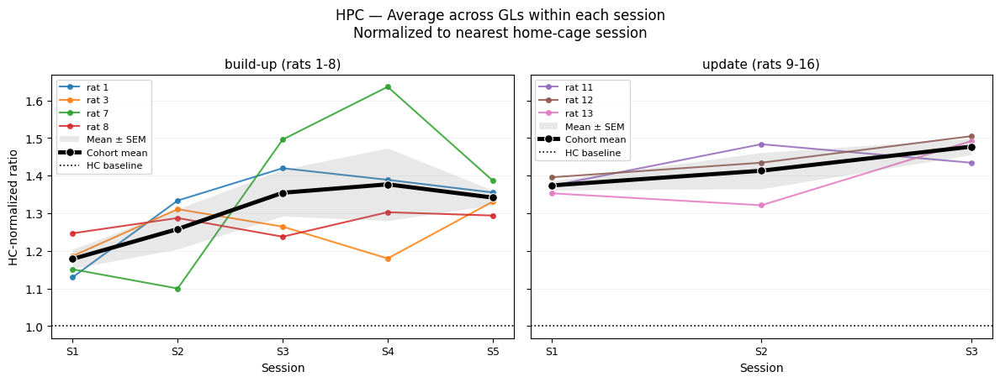

saved: ratio_normalized_avghcnorm_RippleInSpindle_HPC_avg_sessions_per_GL


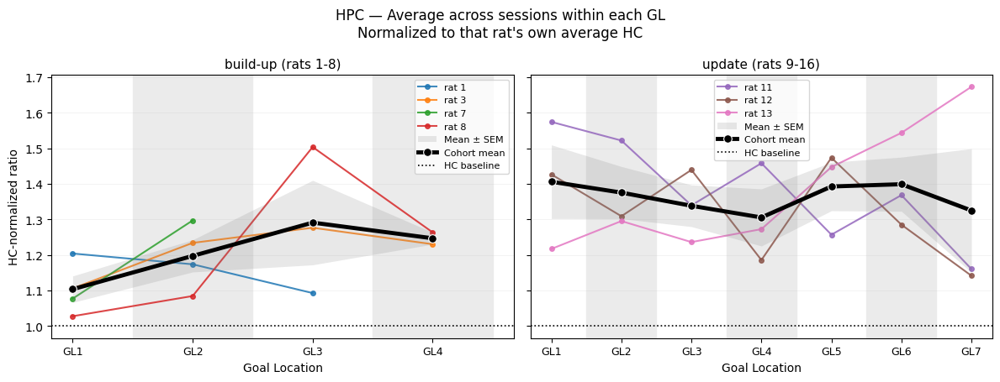

saved: ratio_normalized_avghcnorm_RippleInSpindle_HPC_avg_GLs_per_session


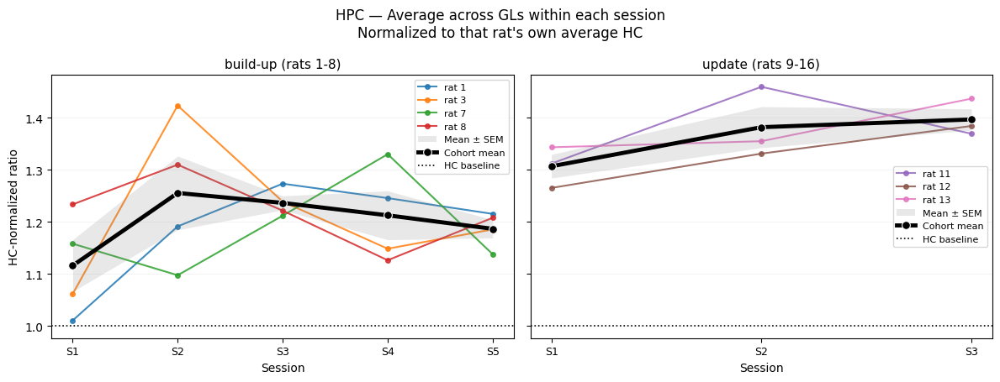

In [78]:
for measure_col, daily_df, hcn_df, avgn_df, label in [
    (
        "prop_ripple_RD",
        prop_rd,
        prop_rd_hcnorm,
        prop_rd_avghcnorm,
        "RippleToDelta",
    ),
    (
        "prop_ripple_DR",
        prop_dr,
        prop_dr_hcnorm,
        prop_dr_avghcnorm,
        "DeltaToRipple",
    ),
    (
        "prop_ripple_spindle",
        prop_sp,
        prop_sp_hcnorm,
        prop_sp_avghcnorm,
        "RippleInSpindle",
    ),
]:

    print(f"=== {label} ===")

    for area in AREAS:

        # ----------------------------------
        # Normalized to nearest HC
        # ----------------------------------

        block_figure_averaged(
            hcn_df,
            area,
            label,
            "normalized_hcnorm",
            "nearest home-cage session",
            average_over="session"
        )

        block_figure_averaged(
            hcn_df,
            area,
            label,
            "normalized_hcnorm",
            "nearest home-cage session",
            average_over="gl"
        )

        # ----------------------------------
        # Normalized to own average HC
        # ----------------------------------

        block_figure_averaged(
            avgn_df,
            area,
            label,
            "normalized_avghcnorm",
            "that rat's own average HC",
            average_over="session"
        )

        block_figure_averaged(
            avgn_df,
            area,
            label,
            "normalized_avghcnorm",
            "that rat's own average HC",
            average_over="gl"
        )

---
# Notes

## Open points

- The per-day circular shift loop was rewritten from the description in `Corrected_Task2_OverTime.ipynb`, not compared with the original cell.